In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('data/manufacturing_defect_dataset.csv')

# Resumo executivo: o que este dataset realmente mostra

Comece por estas tabelas e pelo mapa de calor; o restante notebook e detalhamento exploratorio. O arquivo e **sintetico**, sem datas nem identificadores de fornecedor/lote. `DefectStatus` (baixo/alto nivel) e `DefectRate` (defeitos por 1.000 unidades) sao medidas diferentes: 84% dos registros estarem no nivel alto **nao** significa que 84% das pecas tenham defeito.

O resumo testa quatro perguntas praticas: quais indicadores variam com o status, se manutencao e qualidade juntas separam grupos, se o custo ajuda a explicar a taxa e quanto um modelo melhora em relacao ao baseline da classe majoritaria. Os resultados sao descritivos/validacao interna; nao provam causalidade nem desempenho em fabrica real.

**Achados adicionais:** o status alto salta para cerca de 96% nos dois quintis superiores de `DefectRate`, mas continua acima de 73% nos tres quintis inferiores. No quartil de maior volume, o status alto chega a 95%, enquanto `DefectRate` media e quase identica aos outros quartis. Isso alerta que o rotulo sintetico nao equivale a taxa medida. O custo total tambem e praticamente independente do volume; custo por unidade pode induzir uma falsa leitura de escala.

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# Um quadro de leitura primeiro: classe, taxa continua e indicadores operacionais.
rotulos_insight = {0: "Baixo nivel (0)", 1: "Alto nivel (1)"}
resumo_status_insight = df.groupby("DefectStatus").agg(
    Registros=("DefectStatus", "size"),
    DefectRate_media_defeitos_por_1000=("DefectRate", "mean"),
    DefectRate_mediana_defeitos_por_1000=("DefectRate", "median"),
    Manutencao_horas_semana_media=("MaintenanceHours", "mean"),
    QualityScore_medio=("QualityScore", "mean"),
    Volume_unidades_dia_medio=("ProductionVolume", "mean"),
    Custo_dolares_dia_medio=("ProductionCost", "mean"),
).rename(index=rotulos_insight)
resumo_status_insight["Registros_pct"] = resumo_status_insight["Registros"] / len(df) * 100
print("Comparacao entre os dois niveis de DefectStatus (medias; periodos conforme o dicionario):")
display(resumo_status_insight.round(2))

# Associacao monotona: tamanho de rho importa mais que o p-valor em um dataset grande.
variaveis_chave_insight = [
    "MaintenanceHours", "QualityScore", "ProductionVolume", "DefectRate",
    "ProductionCost", "SupplierQuality",
]
linhas_rho_insight = []
for variavel in variaveis_chave_insight:
    rho_status, _ = spearmanr(df[variavel], df["DefectStatus"])
    rho_rate = np.nan if variavel == "DefectRate" else spearmanr(df[variavel], df["DefectRate"]).statistic
    linhas_rho_insight.append({
        "Indicador": variavel,
        "Spearman_com_DefectStatus": rho_status,
        "Spearman_com_DefectRate": rho_rate,
    })
relacoes_chave_insight = pd.DataFrame(linhas_rho_insight).set_index("Indicador")
print("Correlacoes de Spearman (associacao, nao causalidade):")
display(relacoes_chave_insight.round(3))

# DefectRate vs. todos os indicadores, sem misturar com a classe binaria.
corr_rate_insight = df.drop(columns="DefectStatus").corr(method="spearman")["DefectRate"].drop("DefectRate")
maior_rho_rate_insight = corr_rate_insight.abs().max()
print(f"Maior |rho| entre DefectRate e outro indicador numerico: {maior_rho_rate_insight:.3f} ({corr_rate_insight.abs().idxmax()}).")

volume_total_insight = df["ProductionVolume"].sum()
taxa_ponderada_insight = (df["ProductionVolume"] * df["DefectRate"]).sum() / volume_total_insight
unidades_esperadas_insight = (df["ProductionVolume"] * df["DefectRate"] / 1000).sum()
print(f"DefectRate ponderada pelo volume: {taxa_ponderada_insight:.3f} defeitos/1.000 unidades.")
print(f"Estimativa matematica: {unidades_esperadas_insight:,.0f} unidades defeituosas esperadas (estimativa derivada); nao e uma contagem observada.")

Comparacao entre os dois niveis de DefectStatus (medias; periodos conforme o dicionario):


,Registros,DefectRate_media_defeitos_por_1000,DefectRate_mediana_defeitos_por_1000,Manutencao_horas_semana_media,QualityScore_medio,Volume_unidades_dia_medio,Custo_dolares_dia_medio,Registros_pct
DefectStatus,,,,,,,,
Baixo nivel (0),517,2.01,1.98,6.79,85.44,470.87,12158.88,15.96
Alto nivel (1),2723,2.89,3.03,12.37,79.13,563.27,12473.17,84.04


Correlacoes de Spearman (associacao, nao causalidade):


,Spearman_com_DefectStatus,Spearman_com_DefectRate
Indicador,,
MaintenanceHours,0.297,-0.009
QualityScore,-0.199,-0.036
ProductionVolume,0.130,-0.019
DefectRate,0.244,NaN
ProductionCost,0.027,0.014
SupplierQuality,0.039,0.013


Maior |rho| entre DefectRate e outro indicador numerico: 0.036 (QualityScore).
DefectRate ponderada pelo volume: 2.737 defeitos/1.000 unidades.
Estimativa matematica: 4,864 unidades defeituosas esperadas (estimativa derivada); nao e uma contagem observada.


## Outro achado: o rotulo binario nao acompanha perfeitamente a taxa nem o volume

Dividindo os registros por quintis de `DefectRate`, o status alto passa de aproximadamente 74-79% nos tres grupos inferiores para cerca de 96% nos dois superiores. E um sinal util, mas ainda ha muitos registros com status alto mesmo nas menores taxas. Alem disso, no quartil de maior producao, cerca de 95% dos registros tem status alto, enquanto a `DefectRate` media permanece praticamente igual a dos demais quartis. Isso sugere que `DefectStatus` pode refletir uma regra sintetica ou outros fatores, nao apenas defeitos por 1.000 unidades.

Outro cuidado: `ProductionCost` quase nao varia com o volume neste CSV. O custo derivado por unidade cai quando o volume sobe, mas essa razao pode criar uma aparencia de economia de escala sem que o custo total cresca com a producao. Nao interprete isso como evidencia operacional de eficiencia.

DefectStatus por quintil da taxa (IC95% Wilson):


,Registros,Status_alto_pct,IC95_inf_pct,IC95_sup_pct,DefectRate_media
Quintil_DefectRate,,,,,
Q1 - menor,648,75.46,72.01,78.62,0.95
Q2,648,73.92,70.41,77.15,1.83
Q3,648,78.70,75.39,81.68,2.73
Q4,648,96.14,94.37,97.37,3.66
Q5 - maior,648,95.99,94.19,97.25,4.57



DefectStatus por quartil de volume (IC95% Wilson):


,Registros,Status_alto_pct,IC95_inf_pct,IC95_sup_pct,DefectRate_media,Custo_total_medio_dolares_dia
Quartil_Volume,,,,,,
Q1 - menor,814,81.33,78.50,83.85,2.82,12258.06
Q2,809,80.10,77.21,82.71,2.77,12415.41
Q3,807,79.55,76.63,82.19,2.66,12541.94
Q4 - maior,810,95.19,93.49,96.46,2.75,12477.92


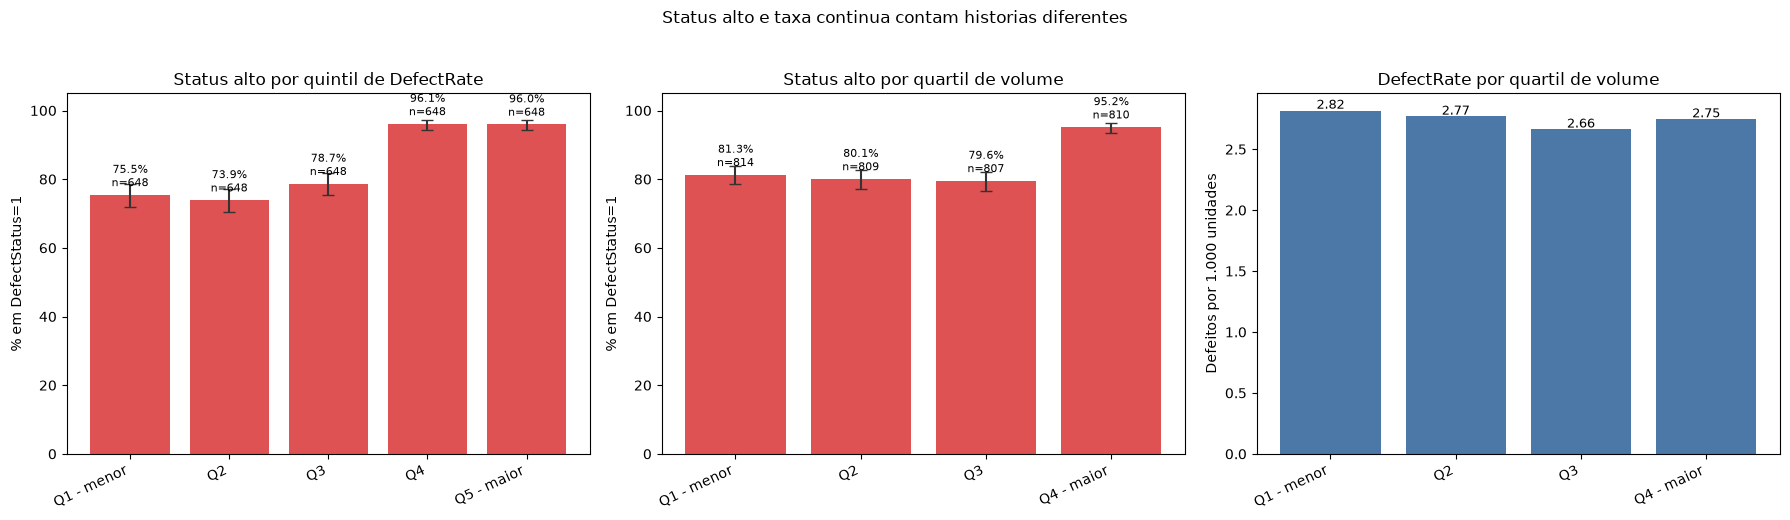

Status alto: 81.3% no menor quartil de volume vs. 95.2% no maior. DefectRate media: 2.82 vs. 2.75 defeitos/1.000.
ProductionCost vs volume: Spearman rho=0.029 (p=0.098); custo/volume vs volume: rho=-0.806. A correlacao da razao e matematicamente influenciada pelo volume no denominador; nao prova economia de escala.


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import spearmanr

# Compare the binary label across observed-rate and volume bands; include uncertainty and n.
dados_bandas_insight = df[["DefectStatus", "DefectRate", "ProductionVolume", "ProductionCost"]].copy()
dados_bandas_insight["Quintil_DefectRate"] = pd.qcut(
    dados_bandas_insight["DefectRate"], 5,
    labels=["Q1 - menor", "Q2", "Q3", "Q4", "Q5 - maior"], duplicates="drop",
)
dados_bandas_insight["Quartil_Volume"] = pd.qcut(
    dados_bandas_insight["ProductionVolume"], 4,
    labels=["Q1 - menor", "Q2", "Q3", "Q4 - maior"], duplicates="drop",
)

def resumir_faixas_insight(coluna_faixa):
    resumo = dados_bandas_insight.groupby(coluna_faixa, observed=True).agg(
        Registros=("DefectStatus", "size"),
        Registros_status_alto=("DefectStatus", "sum"),
        Status_alto_pct=("DefectStatus", lambda s: s.mean() * 100),
        DefectRate_media=("DefectRate", "mean"),
        Volume_medio=("ProductionVolume", "mean"),
        Custo_total_medio_dolares_dia=("ProductionCost", "mean"),
    )
    baixo, alto = proportion_confint(
        resumo["Registros_status_alto"], resumo["Registros"], method="wilson"
    )
    resumo["IC95_inf_pct"] = baixo * 100
    resumo["IC95_sup_pct"] = alto * 100
    return resumo

resumo_rate_insight = resumir_faixas_insight("Quintil_DefectRate")
resumo_volume_insight = resumir_faixas_insight("Quartil_Volume")
print("DefectStatus por quintil da taxa (IC95% Wilson):")
display(resumo_rate_insight[["Registros", "Status_alto_pct", "IC95_inf_pct", "IC95_sup_pct", "DefectRate_media"]].round(2))
print("\nDefectStatus por quartil de volume (IC95% Wilson):")
display(resumo_volume_insight[["Registros", "Status_alto_pct", "IC95_inf_pct", "IC95_sup_pct", "DefectRate_media", "Custo_total_medio_dolares_dia"]].round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, tabela, titulo, ylabel in [
    (axes[0], resumo_rate_insight, "Status alto por quintil de DefectRate", "% em DefectStatus=1"),
    (axes[1], resumo_volume_insight, "Status alto por quartil de volume", "% em DefectStatus=1"),
    (axes[2], resumo_volume_insight, "DefectRate por quartil de volume", "Defeitos por 1.000 unidades"),
]:
    x = range(len(tabela))
    if tabela is resumo_volume_insight and ax is axes[2]:
        valores = tabela["DefectRate_media"].to_numpy()
        ax.bar(x, valores, color="#4c78a8")
        ax.set_xticks(list(x), tabela.index.astype(str), rotation=25, ha="right")
        ax.set_ylabel(ylabel)
        ax.set_title(titulo)
        for pos, valor in zip(x, valores):
            ax.text(pos, valor + 0.015, f"{valor:.2f}", ha="center", fontsize=9)
        continue
    valores = tabela["Status_alto_pct"].to_numpy()
    err = [
        valores - tabela["IC95_inf_pct"].to_numpy(),
        tabela["IC95_sup_pct"].to_numpy() - valores,
    ]
    ax.bar(x, valores, color="#d62728", alpha=0.8)
    ax.errorbar(x, valores, yerr=err, fmt="none", ecolor="#333333", capsize=4)
    ax.set_xticks(list(x), tabela.index.astype(str), rotation=25, ha="right")
    ax.set_ylim(0, 105)
    ax.set_ylabel(ylabel)
    ax.set_title(titulo)
    for pos, valor, n in zip(x, valores, tabela["Registros"]):
        ax.text(pos, valor + 2.5, f"{valor:.1f}%\nn={n}", ha="center", fontsize=8)
fig.suptitle("Status alto e taxa continua contam historias diferentes", y=1.03)
plt.tight_layout()
plt.show()

rho_custo_volume, p_custo_volume = spearmanr(df["ProductionCost"], df["ProductionVolume"])
custo_unitario_derivado = df["ProductionCost"] / df["ProductionVolume"]
rho_custo_unitario_volume, _ = spearmanr(custo_unitario_derivado, df["ProductionVolume"])
q1 = resumo_volume_insight.iloc[0]
q4 = resumo_volume_insight.iloc[-1]
print(
    f"Status alto: {q1['Status_alto_pct']:.1f}% no menor quartil de volume vs. "
    f"{q4['Status_alto_pct']:.1f}% no maior. DefectRate media: "
    f"{q1['DefectRate_media']:.2f} vs. {q4['DefectRate_media']:.2f} defeitos/1.000."
)
print(
    f"ProductionCost vs volume: Spearman rho={rho_custo_volume:.3f} (p={p_custo_volume:.3f}); "
    f"custo/volume vs volume: rho={rho_custo_unitario_volume:.3f}. "
    "A correlacao da razao e matematicamente influenciada pelo volume no denominador; nao prova economia de escala."
)

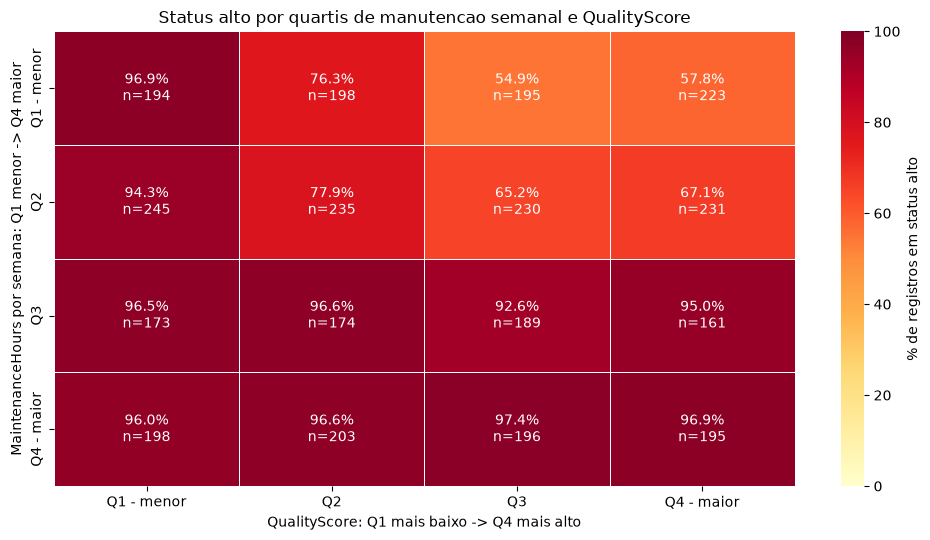

Tabela de apoio: n, proporcao de status alto, IC95% Wilson e DefectRate em defeitos/1.000.


Registros  Status alto (%)  \
Faixa de manutencao Faixa de QualityScore                               
Q1 - menor          Q1 - menor                   194            96.91   
                    Q2                           198            76.26   
                    Q3                           195            54.87   
                    Q4 - maior                   223            57.85   
Q2                  Q1 - menor                   245            94.29   
                    Q2                           235            77.87   
                    Q3                           230            65.22   
                    Q4 - maior                   231            67.10   
Q3                  Q1 - menor                   173            96.53   
                    Q2                           174            96.55   
                    Q3                           189            92.59   
                    Q4 - maior                   161            95.03   
Q4 - maior          Q1 - menor                   198            95.96   
                    Q2                           203            96.55   
                    Q3                           196            97.45   
                    Q4 - maior                   195            96.92   

                                           IC95_inf_pct  IC95_sup_pct  \
Faixa de manutencao Faixa de QualityScore                               
Q1 - menor          Q1 - menor                    93.42         98.57   
                    Q2                            69.87         81.65   
                    Q3                            47.86         61.69   
                    Q4 - maior                    51.29         64.14   
Q2                  Q1 - menor                    90.64         96.57   
                    Q2                            72.14         82.71   
                    Q3                            58.86         71.08   
                    Q4 - maior                    60.80         72.84   
Q3                  Q1 - menor                    92.64         98.40   
                    Q2                            92.68         98.41   
                    Q3                            87.95         95.54   
                    Q4 - maior                    90.50         97.46   
Q4 - maior          Q1 - menor                    92.23         97.94   
                    Q2                            93.05         98.32   
                    Q3                            94.17         98.91   
                    Q4 - maior                    93.45         98.58   

                                           DefectRate_media_defeitos_por_1000  
Faixa de manutencao Faixa de QualityScore                                      
Q1 - menor          Q1 - menor                                           2.85  
                    Q2                                                   2.75  
                    Q3                                                   2.83  
                    Q4 - maior                                           2.74  
Q2                  Q1 - menor                                           2.79  
                    Q2                                                   2.76  
                    Q3                                                   2.63  
                    Q4 - maior                                           2.66  
Q3                  Q1 - menor                                           2.90  
                    Q2                                                   2.76  
                    Q3                                                   2.69  
                    Q4 - maior                                           2.68  
Q4 - maior          Q1 - menor                                           2.72  
                    Q2                                                   2.81  
                    Q3                                                   2.83  
                    Q4 - maior                       

Leitura: a proporcao de status alto nas faixas vai de 71.0% a 96.7%; ja a DefectRate media varia pouco, de 2.71 a 2.79 defeitos/1.000. Nao interprete status binario como contagem/taxa real de defeitos.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportion_confint

# Quartis facilitam a comparacao; cada celula mostra proporcao com nivel alto e n.
faixas_insight = df[["MaintenanceHours", "QualityScore", "DefectStatus", "DefectRate"]].copy()
faixas_insight["Faixa de manutencao"] = pd.qcut(
    faixas_insight["MaintenanceHours"], 4,
    labels=["Q1 - menor", "Q2", "Q3", "Q4 - maior"], duplicates="drop",
)
faixas_insight["Faixa de QualityScore"] = pd.qcut(
    faixas_insight["QualityScore"], 4,
    labels=["Q1 - menor", "Q2", "Q3", "Q4 - maior"], duplicates="drop",
)

grade_insight = faixas_insight.groupby(
    ["Faixa de manutencao", "Faixa de QualityScore"], observed=True
).agg(
    Registros=("DefectStatus", "size"),
    Proporcao_status_alto=("DefectStatus", "mean"),
    DefectRate_media_defeitos_por_1000=("DefectRate", "mean"),
)
grade_insight["Status alto (%)"] = grade_insight["Proporcao_status_alto"] * 100
n_status_alto = (grade_insight["Proporcao_status_alto"] * grade_insight["Registros"]).round().astype(int)
ci_inferior, ci_superior = proportion_confint(n_status_alto, grade_insight["Registros"], method="wilson")
grade_insight["IC95_inf_pct"] = ci_inferior * 100
grade_insight["IC95_sup_pct"] = ci_superior * 100

matriz_status_insight = grade_insight["Status alto (%)"].unstack("Faixa de QualityScore")
matriz_n_insight = grade_insight["Registros"].unstack("Faixa de QualityScore")
anotacoes_insight = matriz_status_insight.copy().astype(object)
for linha in matriz_status_insight.index:
    for coluna in matriz_status_insight.columns:
        anotacoes_insight.loc[linha, coluna] = (
            f"{matriz_status_insight.loc[linha, coluna]:.1f}%\n"
            f"n={matriz_n_insight.loc[linha, coluna]}"
        )

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(
    matriz_status_insight, annot=anotacoes_insight, fmt="", cmap="YlOrRd",
    vmin=0, vmax=100, linewidths=0.5, cbar_kws={"label": "% de registros em status alto"}, ax=ax,
)
ax.set_title("Status alto por quartis de manutencao semanal e QualityScore")
ax.set_xlabel("QualityScore: Q1 mais baixo -> Q4 mais alto")
ax.set_ylabel("MaintenanceHours por semana: Q1 menor -> Q4 maior")
plt.tight_layout()
plt.show()

print("Tabela de apoio: n, proporcao de status alto, IC95% Wilson e DefectRate em defeitos/1.000.")
display(grade_insight[["Registros", "Status alto (%)", "IC95_inf_pct", "IC95_sup_pct", "DefectRate_media_defeitos_por_1000"]].round(2))

menor_manutencao_insight = grade_insight.xs("Q1 - menor", level="Faixa de manutencao")
maior_manutencao_insight = grade_insight.xs("Q4 - maior", level="Faixa de manutencao")
resumo_manutencao_insight = faixas_insight.groupby(
    "Faixa de manutencao", observed=True
).agg(
    Status_alto=("DefectStatus", "mean"),
    DefectRate_media=("DefectRate", "mean"),
)
print(
    "Leitura: a proporcao de status alto nas faixas vai de "
    f"{resumo_manutencao_insight['Status_alto'].min() * 100:.1f}% a "
    f"{resumo_manutencao_insight['Status_alto'].max() * 100:.1f}%; "
    f"ja a DefectRate media varia pouco, de {resumo_manutencao_insight['DefectRate_media'].min():.2f} "
    f"a {resumo_manutencao_insight['DefectRate_media'].max():.2f} defeitos/1.000. "
    "Nao interprete status binario como contagem/taxa real de defeitos."
)

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# DefectRate e omitida: prever DefectStatus usando uma medida diretamente ligada a defeitos
# poderia introduzir vazamento; aqui avaliamos apenas os demais indicadores.
X_validacao_insight = df.select_dtypes(include="number").drop(columns=["DefectStatus", "DefectRate"])
y_validacao_insight = df["DefectStatus"].astype(int)
cv_insight = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelos_insight = {
    "Baseline: classe majoritaria": DummyClassifier(strategy="most_frequent"),
    "Regressao logistica balanceada": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")
    ),
    "Random Forest balanceada": RandomForestClassifier(
        n_estimators=150, min_samples_leaf=15, class_weight="balanced",
        random_state=42, n_jobs=1,
    ),
}
metricas_cv_insight = {
    "Acuracia": "accuracy",
    "Acuracia_balanceada": "balanced_accuracy",
    "Recall_status_baixo": make_scorer(recall_score, pos_label=0, zero_division=0),
    "Recall_status_alto": make_scorer(recall_score, pos_label=1, zero_division=0),
    "ROC_AUC": "roc_auc",
}
linhas_cv_insight = []
for nome, modelo in modelos_insight.items():
    resultado_cv = cross_validate(
        modelo, X_validacao_insight, y_validacao_insight,
        cv=cv_insight, scoring=metricas_cv_insight, n_jobs=1,
    )
    linhas_cv_insight.append({
        "Modelo": nome,
        **{metrica: resultado_cv[f"test_{metrica}"].mean() for metrica in metricas_cv_insight},
    })
comparacao_cv_insight = pd.DataFrame(linhas_cv_insight).set_index("Modelo")
print("Validacao cruzada estratificada (5 folds); recall avalia cada classe separadamente:")
display(comparacao_cv_insight.round(3))
modelo_taxa_isolada = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")
)
resultado_taxa_isolada = cross_validate(
    modelo_taxa_isolada, df[["DefectRate"]], y_validacao_insight,
    cv=cv_insight, scoring="roc_auc", n_jobs=1,
)
print(f"ROC-AUC usando apenas DefectRate: {resultado_taxa_isolada['test_score'].mean():.3f}")
print(
    "A acuracia do baseline e alta porque 84% dos registros estao na classe 1; "
    "use acuracia balanceada e recall do status baixo para avaliar ganho real. "
    "DefectRate isolada tem algum sinal para classificar o status, mas nao explica o status perfeitamente. "
    "Validacao interna em dados sinteticos nao garante desempenho em producao."
)

Validacao cruzada estratificada (5 folds); recall avalia cada classe separadamente:


,Acuracia,Acuracia_balanceada,Recall_status_baixo,Recall_status_alto,ROC_AUC
Modelo,,,,,
Baseline: classe majoritaria,0.840,0.500,0.000,1.000,0.500
Regressao logistica balanceada,0.720,0.729,0.743,0.715,0.793
Random Forest balanceada,0.869,0.839,0.795,0.883,0.839


ROC-AUC usando apenas DefectRate: 0.692
A acuracia do baseline e alta porque 84% dos registros estao na classe 1; use acuracia balanceada e recall do status baixo para avaliar ganho real. DefectRate isolada tem algum sinal para classificar o status, mas nao explica o status perfeitamente. Validacao interna em dados sinteticos nao garante desempenho em producao.


## Entendendo o DataFrame original (`df`)

O conjunto e **sintetico**, criado para fins educacionais. Cada linha traz indicadores de producao; as descricoes da fonte usam periodos diferentes (dia, semana e mes), e nao ha uma coluna de data, ID de lote ou identificador/nome de fornecedor. Portanto, nao e possivel acompanhar sazonalidade nem atribuir registros a fornecedores reais.

`SupplierQuality` e uma pontuacao percentual (nao um identificador). `DefectRate` mede defeitos por 1.000 unidades; nao e uma porcentagem. `DefectStatus` e uma classe de nivel: **0 = baixo nivel de defeitos** e **1 = alto nivel de defeitos** - nao significa ausencia/presenca de defeitos. No CSV, a classe 1 representa 2.723 de 3.240 registros (84,04%), embora o cartao descreva o conjunto como desbalanceado; a distribuicao observada deve guiar a analise.

As estimativas de unidades defeituosas usam `ProductionVolume * DefectRate / 1000` e representam uma estimativa derivada da taxa, nao uma contagem observada. Resultados de correlacao e modelos sao exploratorios: o dataset sintetico nao demonstra causalidade nem garante desempenho em uma fabrica real.

In [7]:
import re
# Visao geral: tamanho, valores ausentes, duplicatas e distribuicao do alvo.
print(f"Dimensoes: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas duplicadas completas: {df.duplicated().sum()}")
print(f"Valores ausentes: {int(df.isna().sum().sum())}")
print()
print("Distribuicao de DefectStatus (0=baixo nivel; 1=alto nivel de defeitos):")
contagem_status = df["DefectStatus"].value_counts().sort_index()
resumo_status = pd.DataFrame({
    "registros": contagem_status,
    "percentual": (contagem_status / len(df) * 100).round(2),
})
display(resumo_status)
print()
print("Campos de identificacao/data encontrados:")
campos_identificacao = [
    coluna for coluna in df.columns
    if re.search(
        r"(^|_)(id|date|data|timestamp|year|ano|month|mes|day|dia|suppliername|vendor)(_|$)",
        coluna.lower(),
    )
]
print(campos_identificacao if campos_identificacao else "Nenhum ID de fornecedor/lote ou campo de data")

Dimensoes: 3240 linhas x 17 colunas
Linhas duplicadas completas: 0
Valores ausentes: 0

Distribuicao de DefectStatus (0=baixo nivel; 1=alto nivel de defeitos):


,registros,percentual
DefectStatus,,
0,517,15.96
1,2723,84.04



Campos de identificacao/data encontrados:
Nenhum ID de fornecedor/lote ou campo de data


In [8]:
# Dicionario conforme a documentacao fornecida para o dataset.
dicionario_df = pd.DataFrame([
    ("ProductionVolume", "Volume de producao", "unidades por dia; faixa documentada 100-1.000"),
    ("ProductionCost", "Custo de producao", "dolares por dia; faixa documentada US$ 5.000-20.000"),
    ("SupplierQuality", "Pontuacao de qualidade do fornecedor", "percentual; 80%-100%; nao identifica fornecedor"),
    ("DeliveryDelay", "Atraso medio de entrega", "dias; 0-5"),
    ("DefectRate", "Taxa de defeitos", "defeitos por 1.000 unidades; 0,5-5,0; nao e percentual"),
    ("QualityScore", "Pontuacao geral de qualidade", "percentual; 60%-100%"),
    ("MaintenanceHours", "Horas de manutencao", "horas por semana; 0-24"),
    ("DowntimePercentage", "Percentual de parada da producao", "percentual; 0%-5%"),
    ("InventoryTurnover", "Giro de estoque", "razao; 2-10"),
    ("StockoutRate", "Taxa de falta de estoque", "documentada como 0%-10%; valores brutos do CSV chegam a ~0,1, possivelmente fracao; confirmar escala antes de converter"),
    ("WorkerProductivity", "Produtividade dos trabalhadores", "percentual; 80%-100%"),
    ("SafetyIncidents", "Incidentes de seguranca", "incidentes por mes; 0-10"),
    ("EnergyConsumption", "Consumo de energia", "kWh; documentacao nao especifica periodo"),
    ("EnergyEfficiency", "Fator de eficiencia energetica", "fator; 0,1-0,5"),
    ("AdditiveProcessTime", "Tempo do processo aditivo", "horas; 1-10"),
    ("AdditiveMaterialCost", "Custo do material aditivo", "dolares por unidade; US$ 100-500"),
    ("DefectStatus", "Classe binaria de nivel de defeitos", "0 = baixo nivel; 1 = alto nivel; nao indica ausencia/presenca"),
], columns=["coluna", "interpretacao", "unidade, periodo ou observacao"])
display(dicionario_df)

,coluna,interpretacao,"unidade, periodo ou observacao"
0,ProductionVolume,Volume de producao,unidades por dia; faixa documentada 100-1.000
1,ProductionCost,Custo de producao,dolares por dia; faixa documentada US$ 5.000-2...
2,SupplierQuality,Pontuacao de qualidade do fornecedor,percentual; 80%-100%; nao identifica fornecedor
3,DeliveryDelay,Atraso medio de entrega,dias; 0-5
4,DefectRate,Taxa de defeitos,"defeitos por 1.000 unidades; 0,5-5,0; nao e pe..."
5,QualityScore,Pontuacao geral de qualidade,percentual; 60%-100%
6,MaintenanceHours,Horas de manutencao,horas por semana; 0-24
7,DowntimePercentage,Percentual de parada da producao,percentual; 0%-5%
8,InventoryTurnover,Giro de estoque,razao; 2-10
9,StockoutRate,Taxa de falta de estoque,documentada como 0%-10%; valores brutos do CSV...


In [9]:
# Veja poucas linhas e apenas campos centrais, em vez de despejar todo o dataset.
colunas_leitura = [
    "ProductionVolume", "ProductionCost", "SupplierQuality",
    "DefectRate", "QualityScore", "MaintenanceHours", "DefectStatus",
]
amostra_df = df[colunas_leitura].head(8).copy()
amostra_df["Interpretacao de DefectStatus"] = amostra_df["DefectStatus"].map({
    0: "baixo nivel de defeitos",
    1: "alto nivel de defeitos",
})
display(amostra_df)
print("Cada linha e um registro sintetico. Nao ha fornecedor, lote ou data identificavel; as variaveis tambem podem usar periodos diferentes.")

,ProductionVolume,ProductionCost,SupplierQuality,DefectRate,QualityScore,MaintenanceHours,DefectStatus,Interpretacao de DefectStatus
0,202,13175.403783,86.648534,3.121492,63.463494,9,1,alto nivel de defeitos
1,535,19770.046093,86.310664,0.819531,83.697818,20,1,alto nivel de defeitos
2,960,19060.820997,82.132472,4.514504,90.350550,1,1,alto nivel de defeitos
3,370,5647.606037,87.335966,0.638524,67.628690,8,1,alto nivel de defeitos
4,206,7472.222236,81.989893,3.867784,82.728334,9,1,alto nivel de defeitos
5,171,6975.931602,95.331919,3.914574,92.568436,19,1,alto nivel de defeitos
6,800,15889.698650,99.325486,4.789000,90.729911,10,1,alto nivel de defeitos
7,120,17266.779948,99.401489,0.743605,92.119681,13,1,alto nivel de defeitos


Cada linha e um registro sintetico. Nao ha fornecedor, lote ou data identificavel; as variaveis tambem podem usar periodos diferentes.


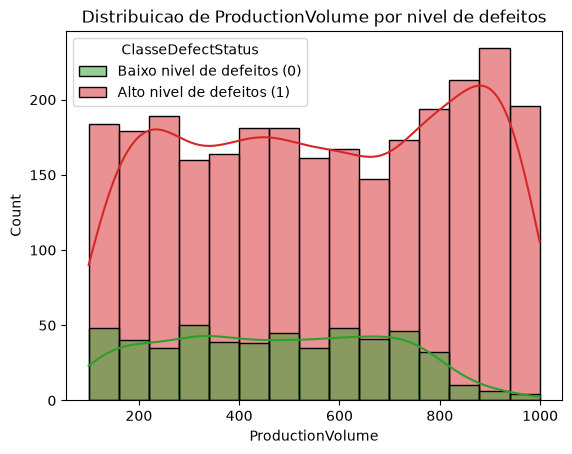

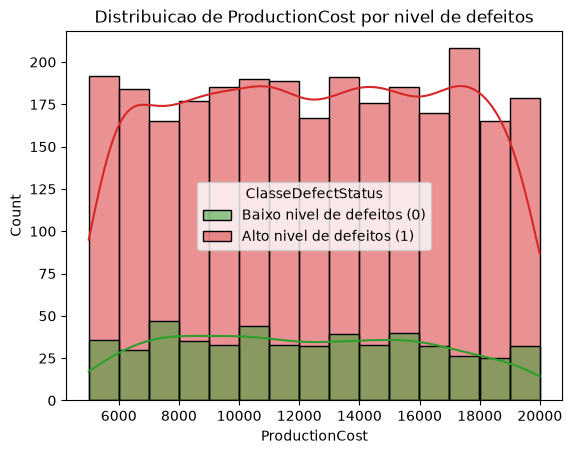

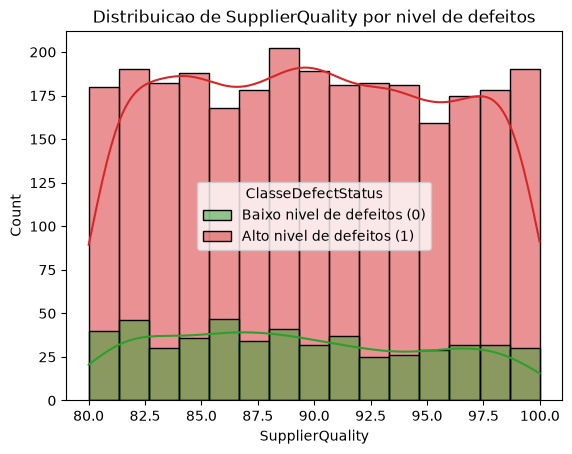

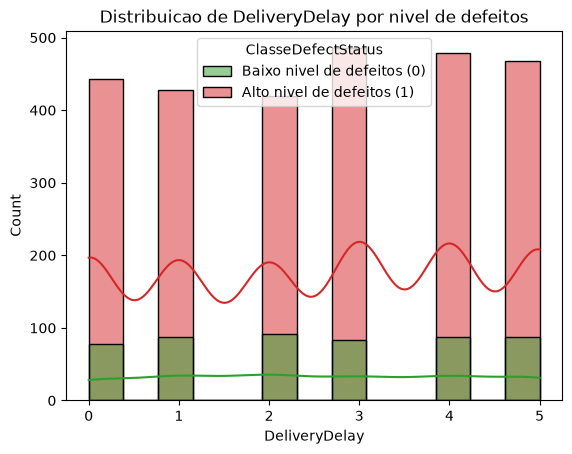

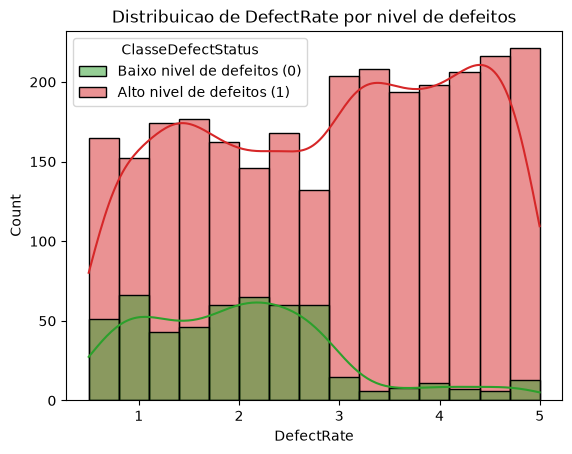

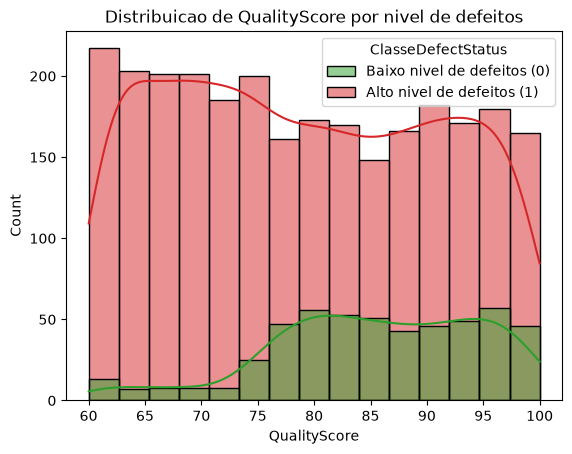

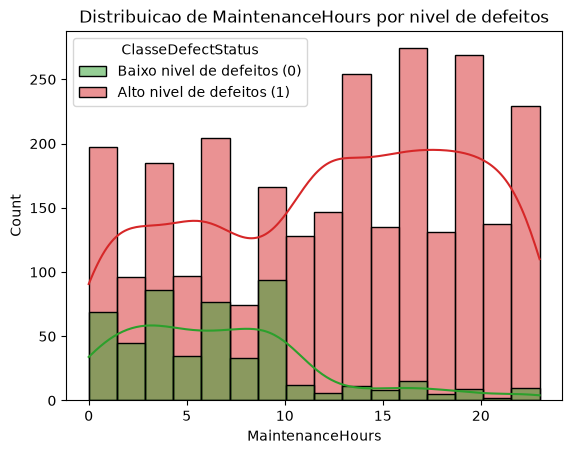

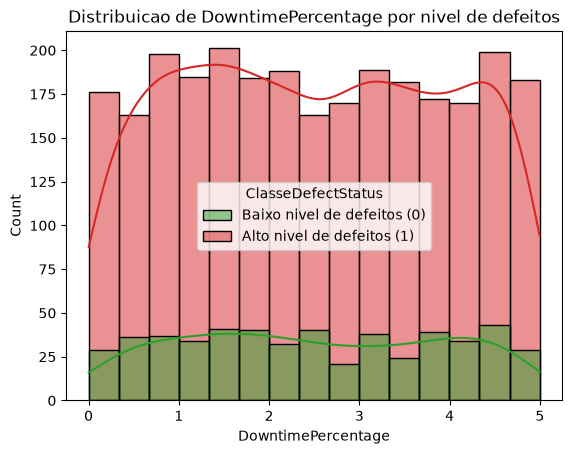

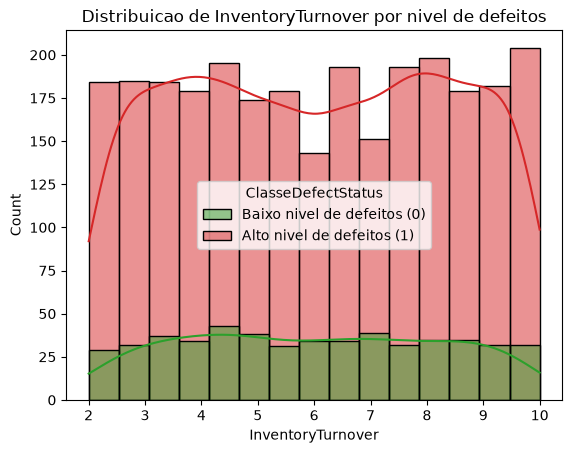

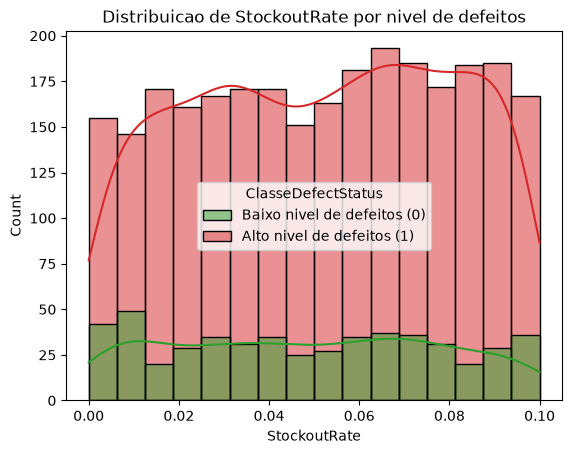

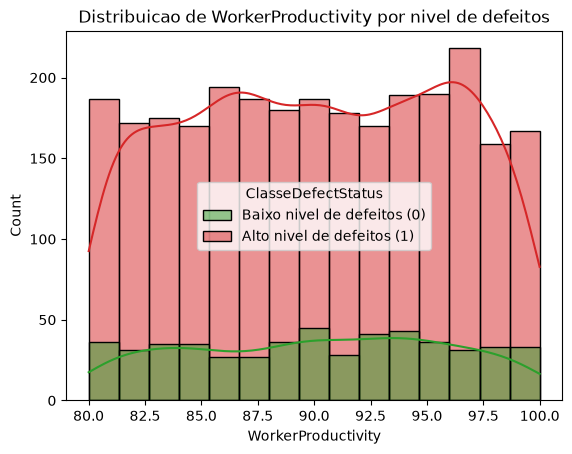

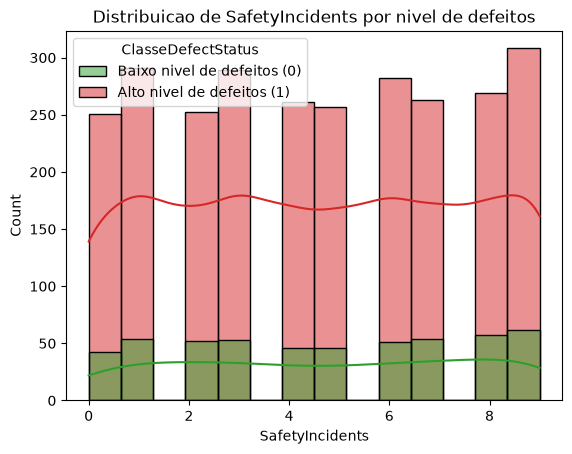

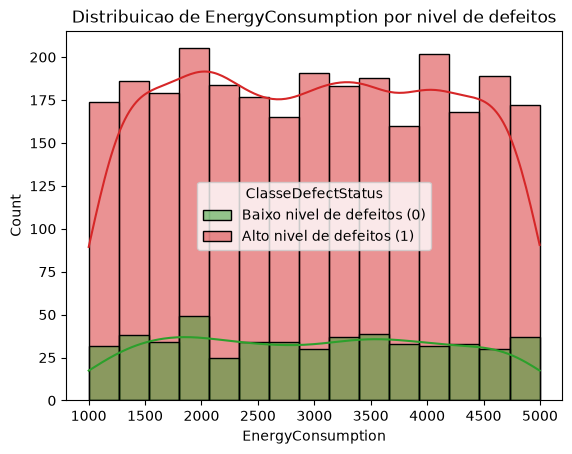

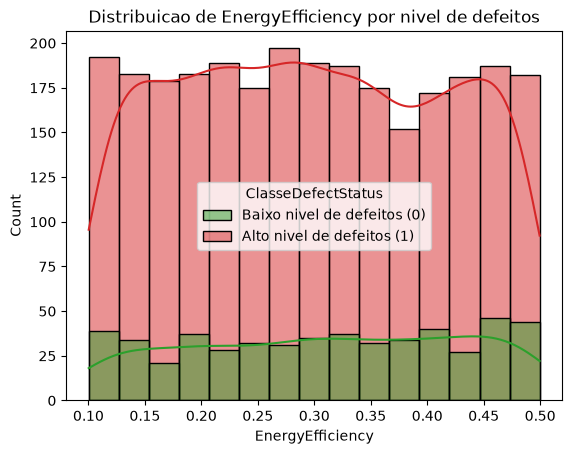

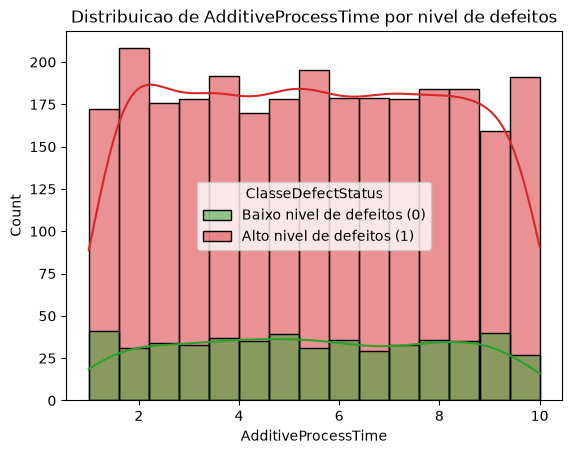

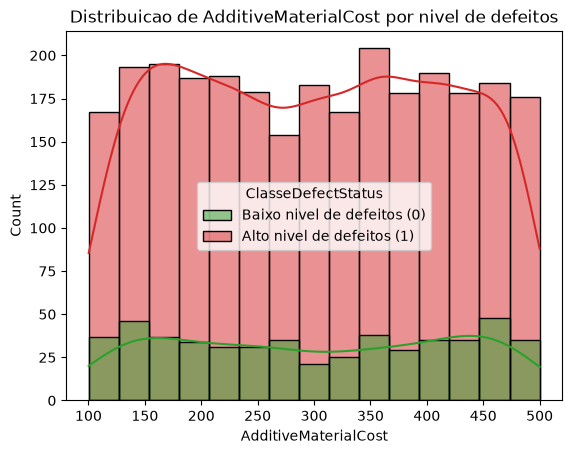

In [10]:
rotulos_defect_status = {0: "Baixo nivel de defeitos (0)", 1: "Alto nivel de defeitos (1)"}
cores_defect_status = {
    "Baixo nivel de defeitos (0)": "#2ca02c",
    "Alto nivel de defeitos (1)": "#d62728",
}
dados_hist = df.copy()
dados_hist["ClasseDefectStatus"] = dados_hist["DefectStatus"].map(rotulos_defect_status)
for col in df.select_dtypes(include=["int64", "float64"]).columns.drop("DefectStatus", errors="ignore"):
    sns.histplot(
        data=dados_hist,
        x=col,
        hue="ClasseDefectStatus",
        hue_order=list(cores_defect_status),
        palette=cores_defect_status,
        kde=True,
    )
    plt.title(f"Distribuicao de {col} por nivel de defeitos")
    plt.show()

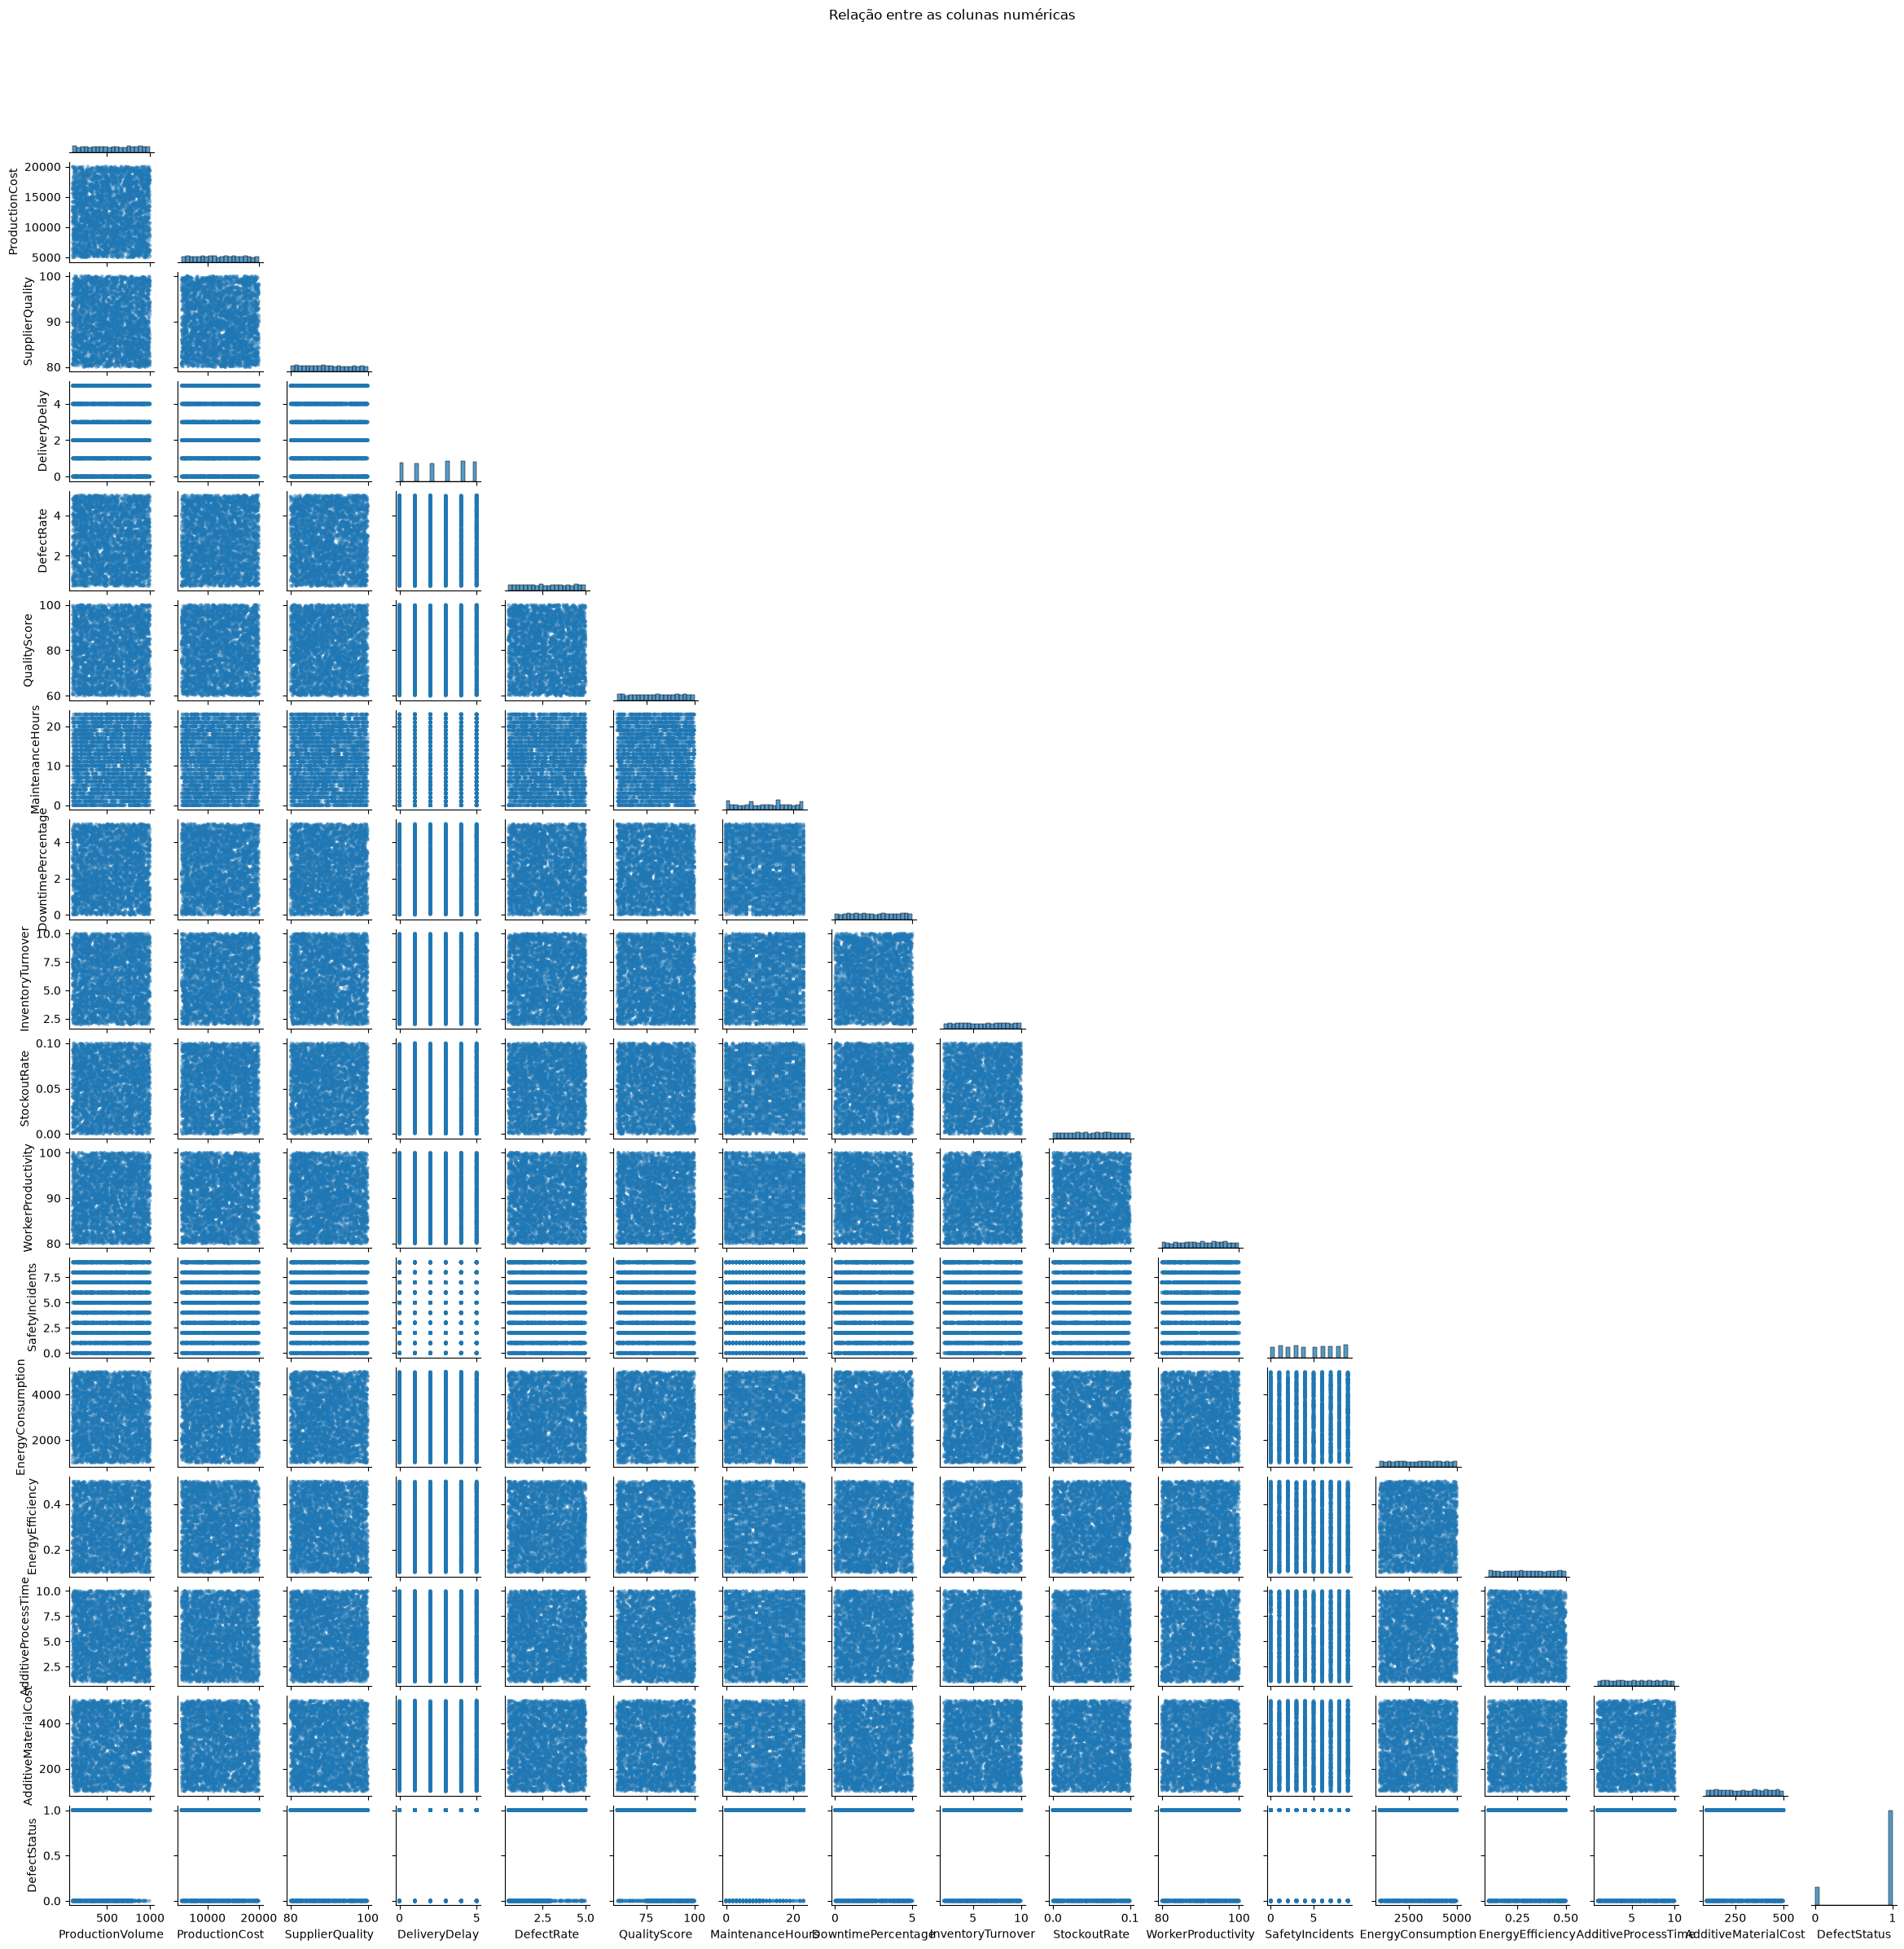

In [11]:
# Matriz de dispers?o: cada coluna num?rica comparada com as demais.
colunas_numericas = df.select_dtypes(include="number").columns

matriz = sns.pairplot(
    data=df,
    vars=colunas_numericas,
    corner=True,
    diag_kind="hist",
    height=1.4,
    plot_kws={"alpha": 0.5, "s": 12, "edgecolor": "none"},
    diag_kws={"bins": 20},
)
matriz.fig.suptitle("Relação entre as colunas numéricas", y=1.01)
plt.show()

## Distribui??es dos indicadores num?ricos

Histogramas com curva de densidade para cada indicador num?rico, sem incluir `DefectStatus`, que ? uma vari?vel categ?rica.

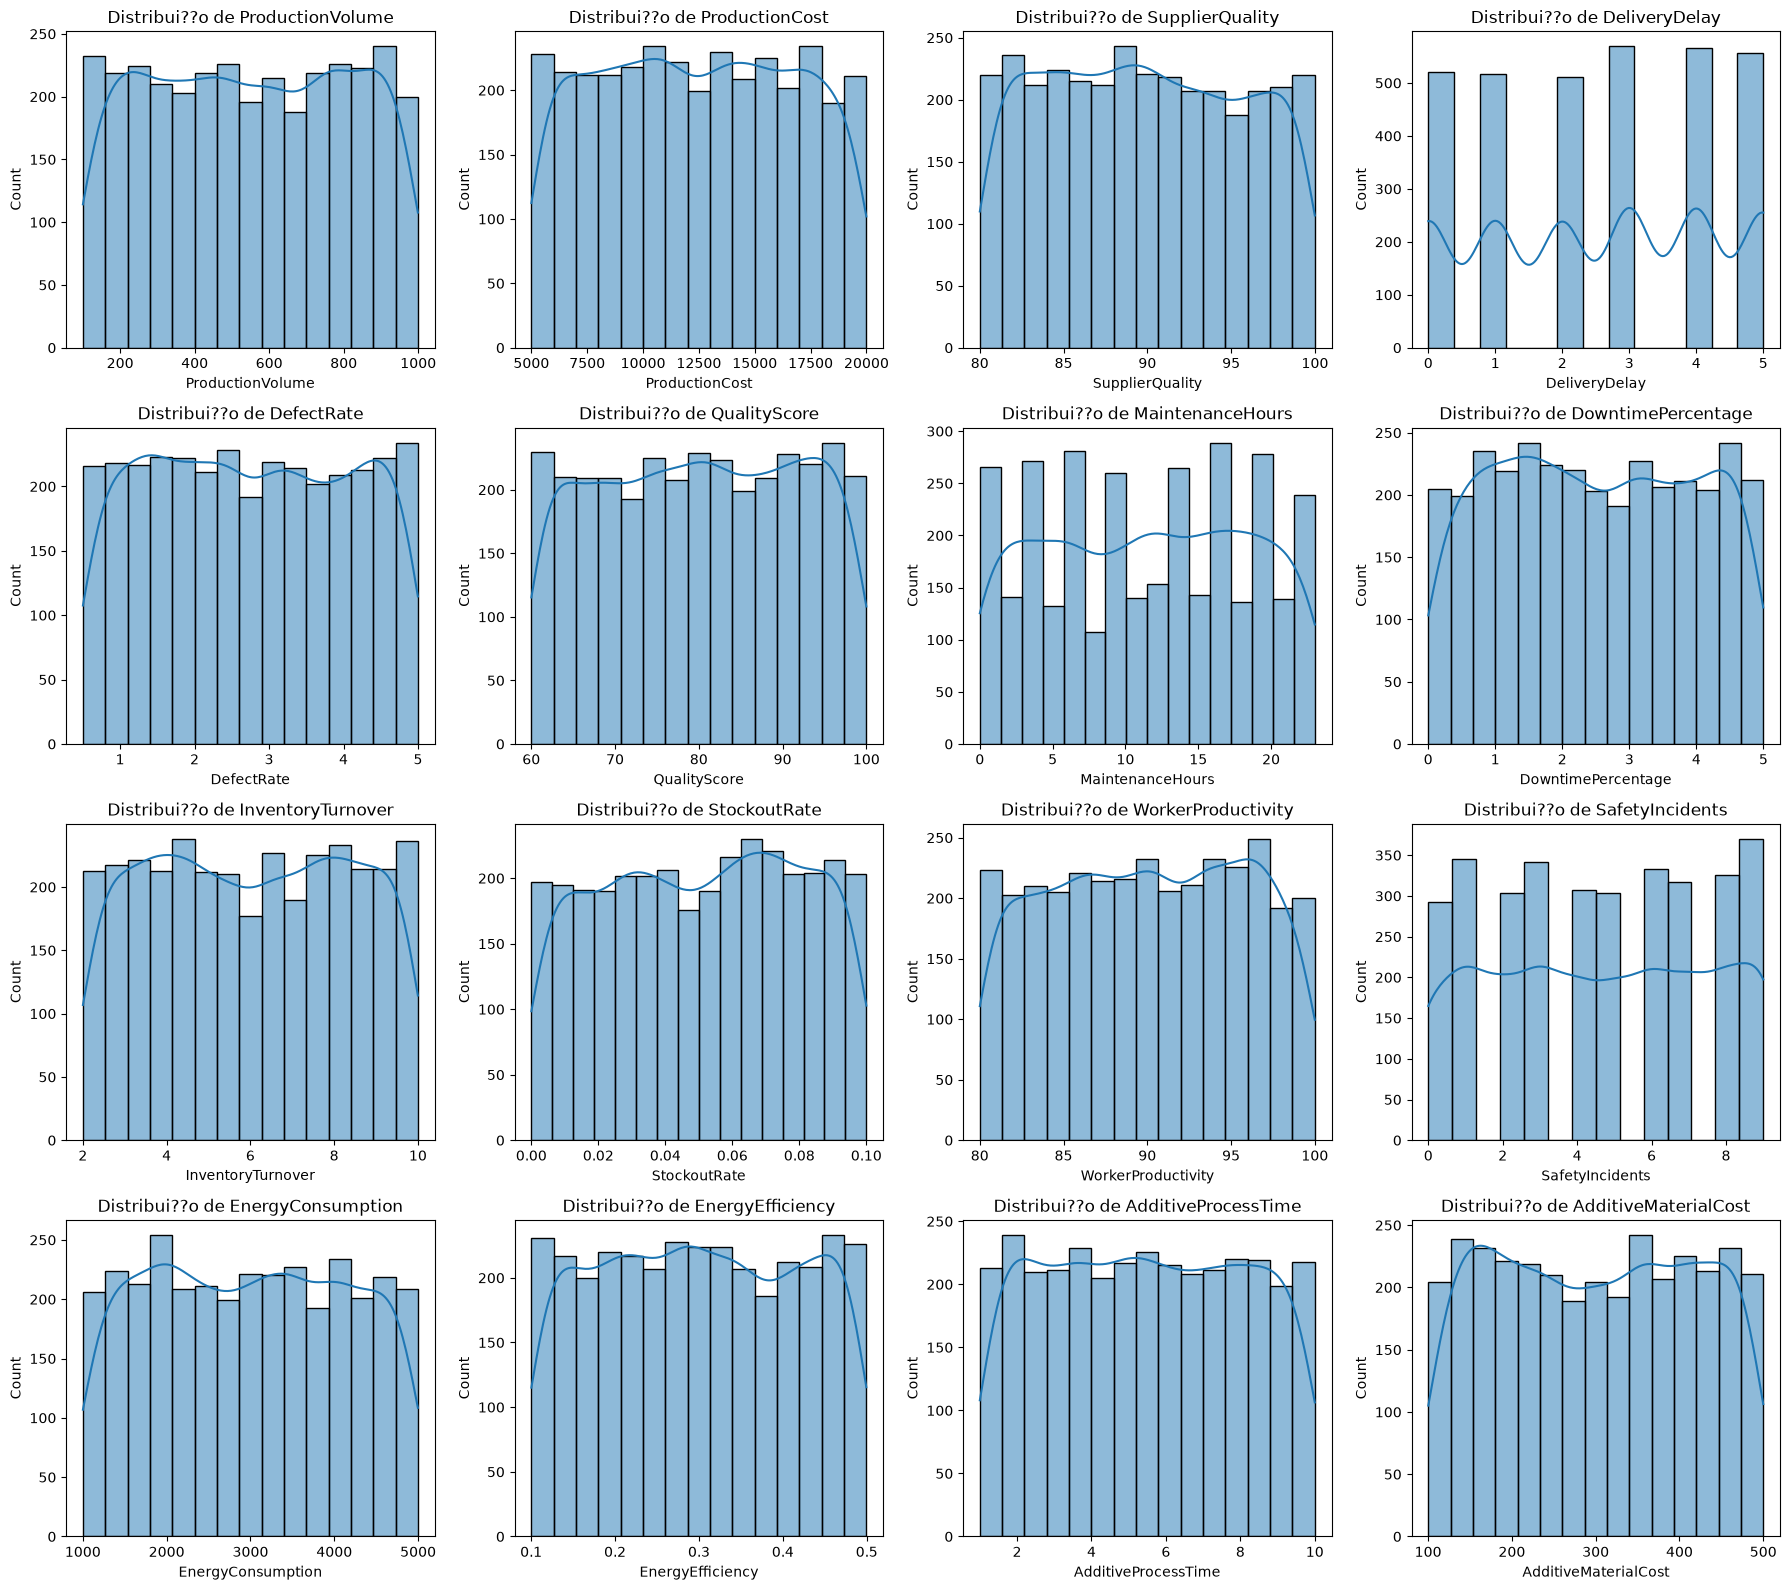

In [12]:
colunas_numericas = df.select_dtypes(include="number").columns.drop("DefectStatus", errors="ignore")
linhas = (len(colunas_numericas) + 3) // 4
fig, axes = plt.subplots(linhas, 4, figsize=(18, 4 * linhas))
axes = axes.flatten()

for ax, coluna in zip(axes, colunas_numericas):
    sns.histplot(data=df, x=coluna, kde=True, ax=ax)
    ax.set_title(f"Distribui??o de {coluna}")

for ax in axes[len(colunas_numericas):]:
    ax.remove()

plt.tight_layout()
plt.show()

## Boxplots por categoria de defeito

Cada boxplot compara um indicador entre os grupos de `DefectStatus` (0 e 1). Os pontos fora dos bigodes foram ocultados para facilitar a leitura; eles continuam fazendo parte dos dados e das demais an?lises.

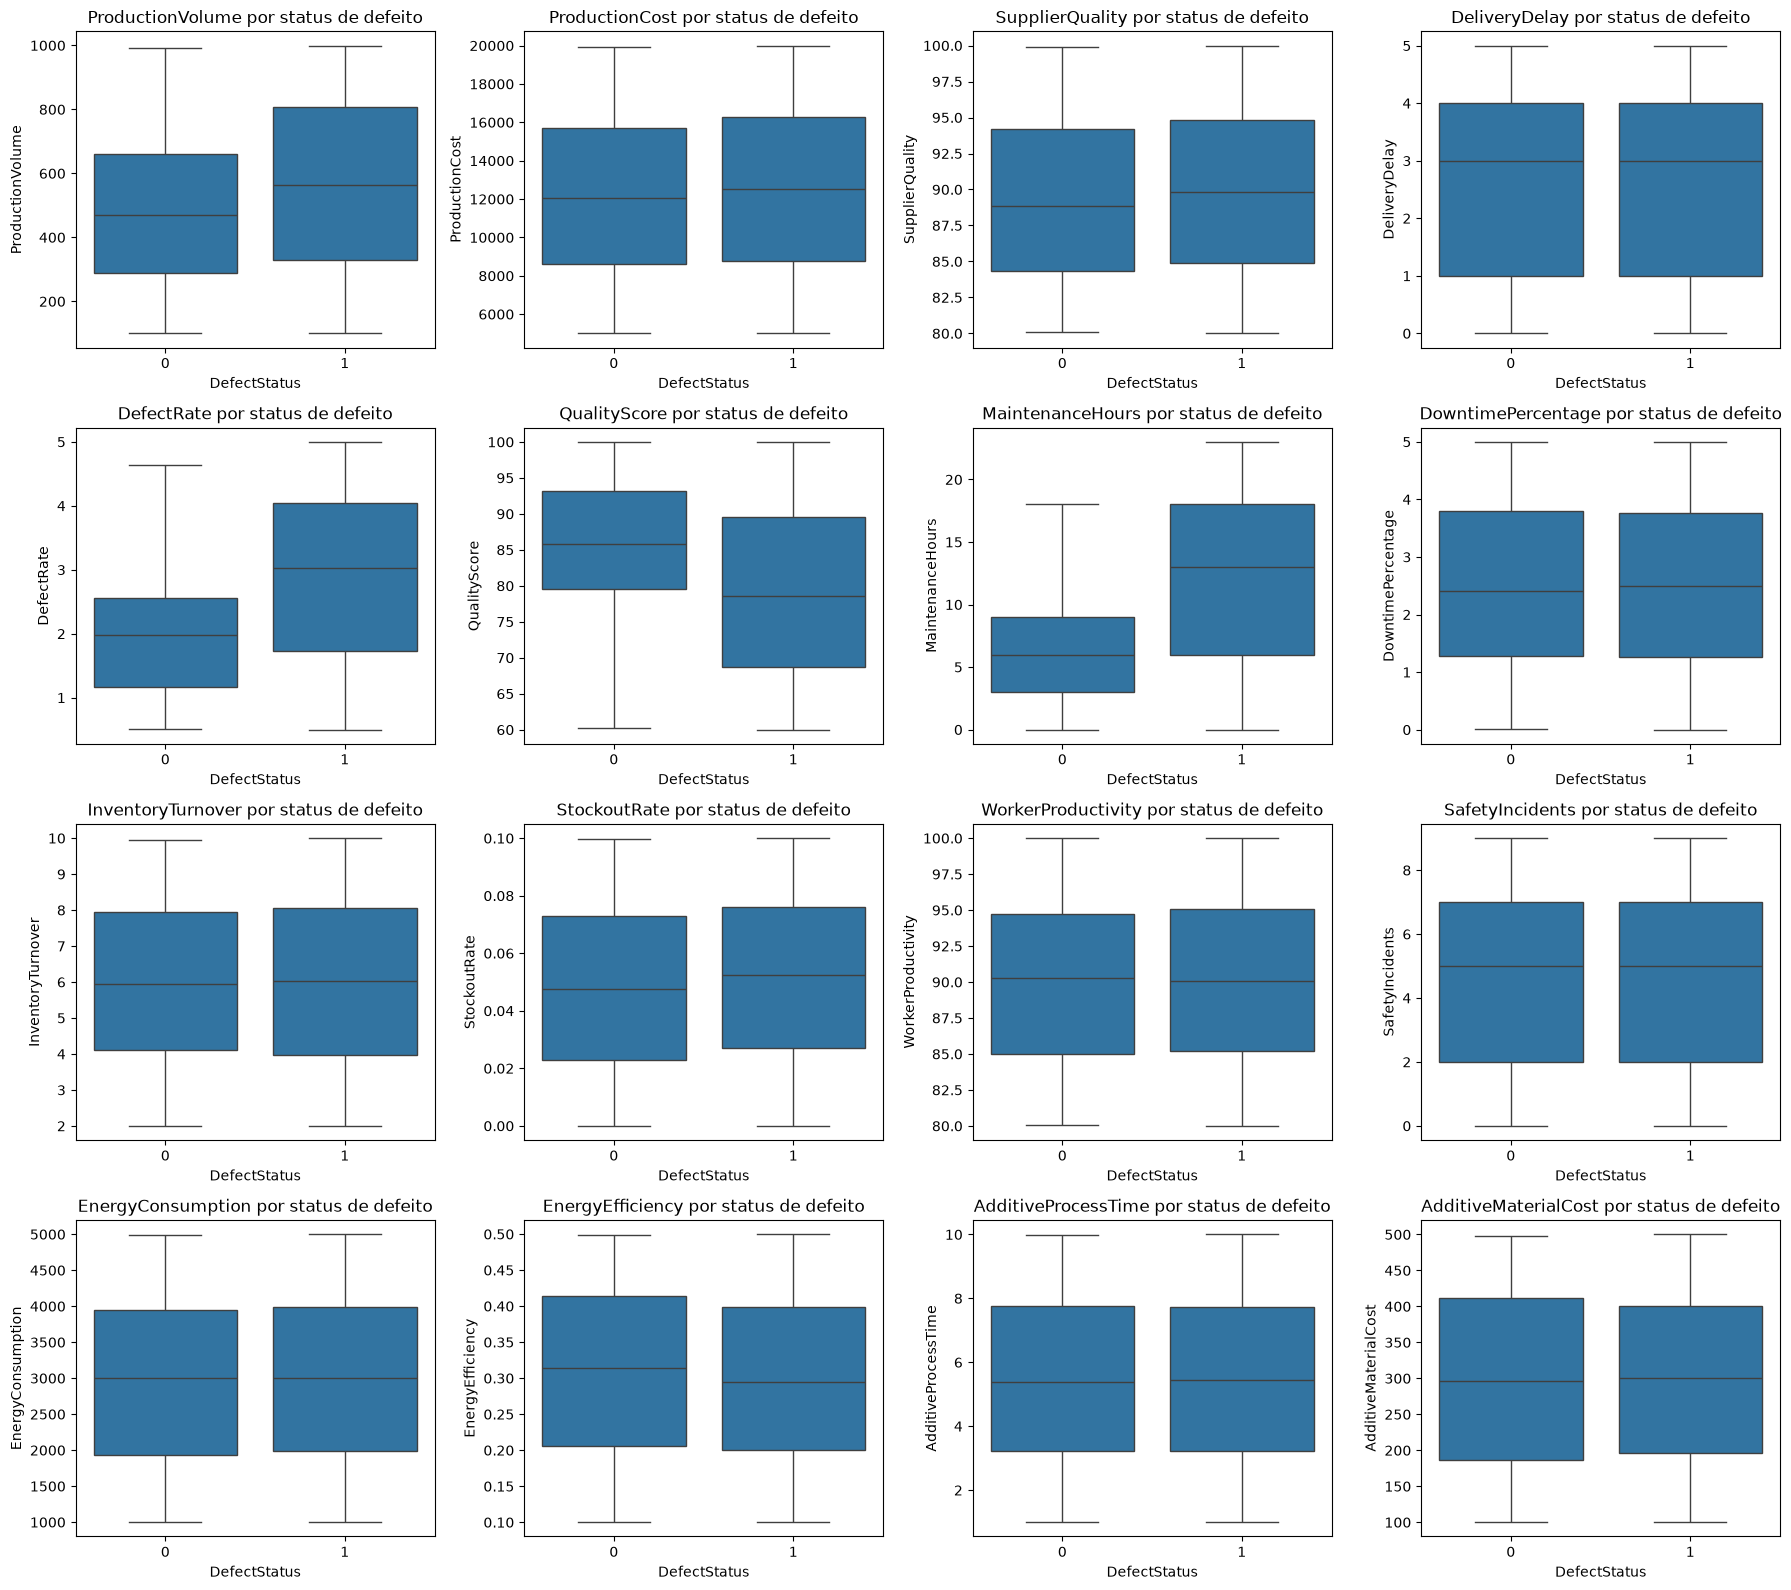

In [13]:
fig, axes = plt.subplots(linhas, 4, figsize=(18, 4 * linhas))
axes = axes.flatten()

for ax, coluna in zip(axes, colunas_numericas):
    sns.boxplot(data=df, x="DefectStatus", y=coluna, showfliers=False, ax=ax)
    ax.set_title(f"{coluna} por status de defeito")
    ax.set_xlabel("DefectStatus")

for ax in axes[len(colunas_numericas):]:
    ax.remove()

plt.tight_layout()
plt.show()

## Regressao logistica para `DefectStatus`

O alvo tem dois niveis: 0 = baixo nivel de defeitos e 1 = alto nivel de defeitos. `DefectRate` fica fora dos preditores por estar diretamente ligada ao resultado e poder causar vazamento de informacao. Os coeficientes e odds ratios usam preditores padronizados; a analise e associativa e nao demonstra causalidade.

In [14]:
import numpy as np
import statsmodels.api as sm

alvo = "DefectStatus"
preditores = [
    coluna
    for coluna in colunas_numericas
    if coluna not in {alvo, "DefectRate"}
]
dados_modelo = df[[alvo, *preditores]].dropna().copy()
X = dados_modelo[preditores].astype(float)
desvios = X.std(ddof=0)
preditores_validos = desvios[desvios > 0].index
X = (X[preditores_validos] - X[preditores_validos].mean()) / desvios[preditores_validos]
X = sm.add_constant(X)
y = dados_modelo[alvo].astype(int)

modelo_logistico = sm.GLM(y, X, family=sm.families.Binomial()).fit()
intervalos = modelo_logistico.conf_int()
resultado_logistico = pd.DataFrame({
    "coeficiente": modelo_logistico.params,
    "odds_ratio": np.exp(modelo_logistico.params),
    "OR_IC95_inferior": np.exp(intervalos[0]),
    "OR_IC95_superior": np.exp(intervalos[1]),
    "p_valor": modelo_logistico.pvalues,
}).drop(index="const", errors="ignore").sort_values("p_valor")

display(resultado_logistico)
print(f"Observa??es usadas: {len(dados_modelo)}")
print(f"AIC: {modelo_logistico.aic:.2f}")
print(f"Pseudo-R? (McFadden): {1 - modelo_logistico.deviance / modelo_logistico.null_deviance:.4f}")

,coeficiente,odds_ratio,OR_IC95_inferior,OR_IC95_superior,p_valor
MaintenanceHours,0.983937,2.674967,2.372085,3.016523,5.880728e-58
QualityScore,-0.648261,0.522955,0.467861,0.584535,3.585756e-30
ProductionVolume,0.440304,1.553179,1.395652,1.728487,7.052973e-16
SupplierQuality,0.126033,1.134319,1.022789,1.258012,1.700178e-02
StockoutRate,0.092835,1.097281,0.989968,1.216227,7.706845e-02
EnergyEfficiency,-0.088135,0.915637,0.826007,1.014994,9.358015e-02
ProductionCost,0.061264,1.063180,0.957887,1.180046,2.495801e-01
SafetyIncidents,-0.060460,0.941331,0.848013,1.044919,2.563498e-01
AdditiveProcessTime,0.049857,1.051121,0.948318,1.165068,3.423988e-01
EnergyConsumption,0.024760,1.025069,0.924440,1.136652,6.386002e-01


Observa??es usadas: 3240
AIC: 2349.63
Pseudo-R? (McFadden): 0.1852


## ANACOR: faixas dos indicadores e `DefectStatus`

Cada ANACOR cruza as faixas de um indicador numerico com as duas classes documentadas de `DefectStatus` (0 = baixo nivel; 1 = alto nivel de defeitos). Os indicadores sao divididos em tercis (`Baixo`, `Medio`, `Alto`); o proprio `DefectStatus` nao e dividido em faixas. A tabela resume qui-quadrado, p-valor, menor frequencia esperada e inercia. Como o status tem apenas duas categorias, cada mapa tem no maximo uma dimensao informativa. Os testes sao exploratorios e nao tem ajuste de multiplas comparacoes.

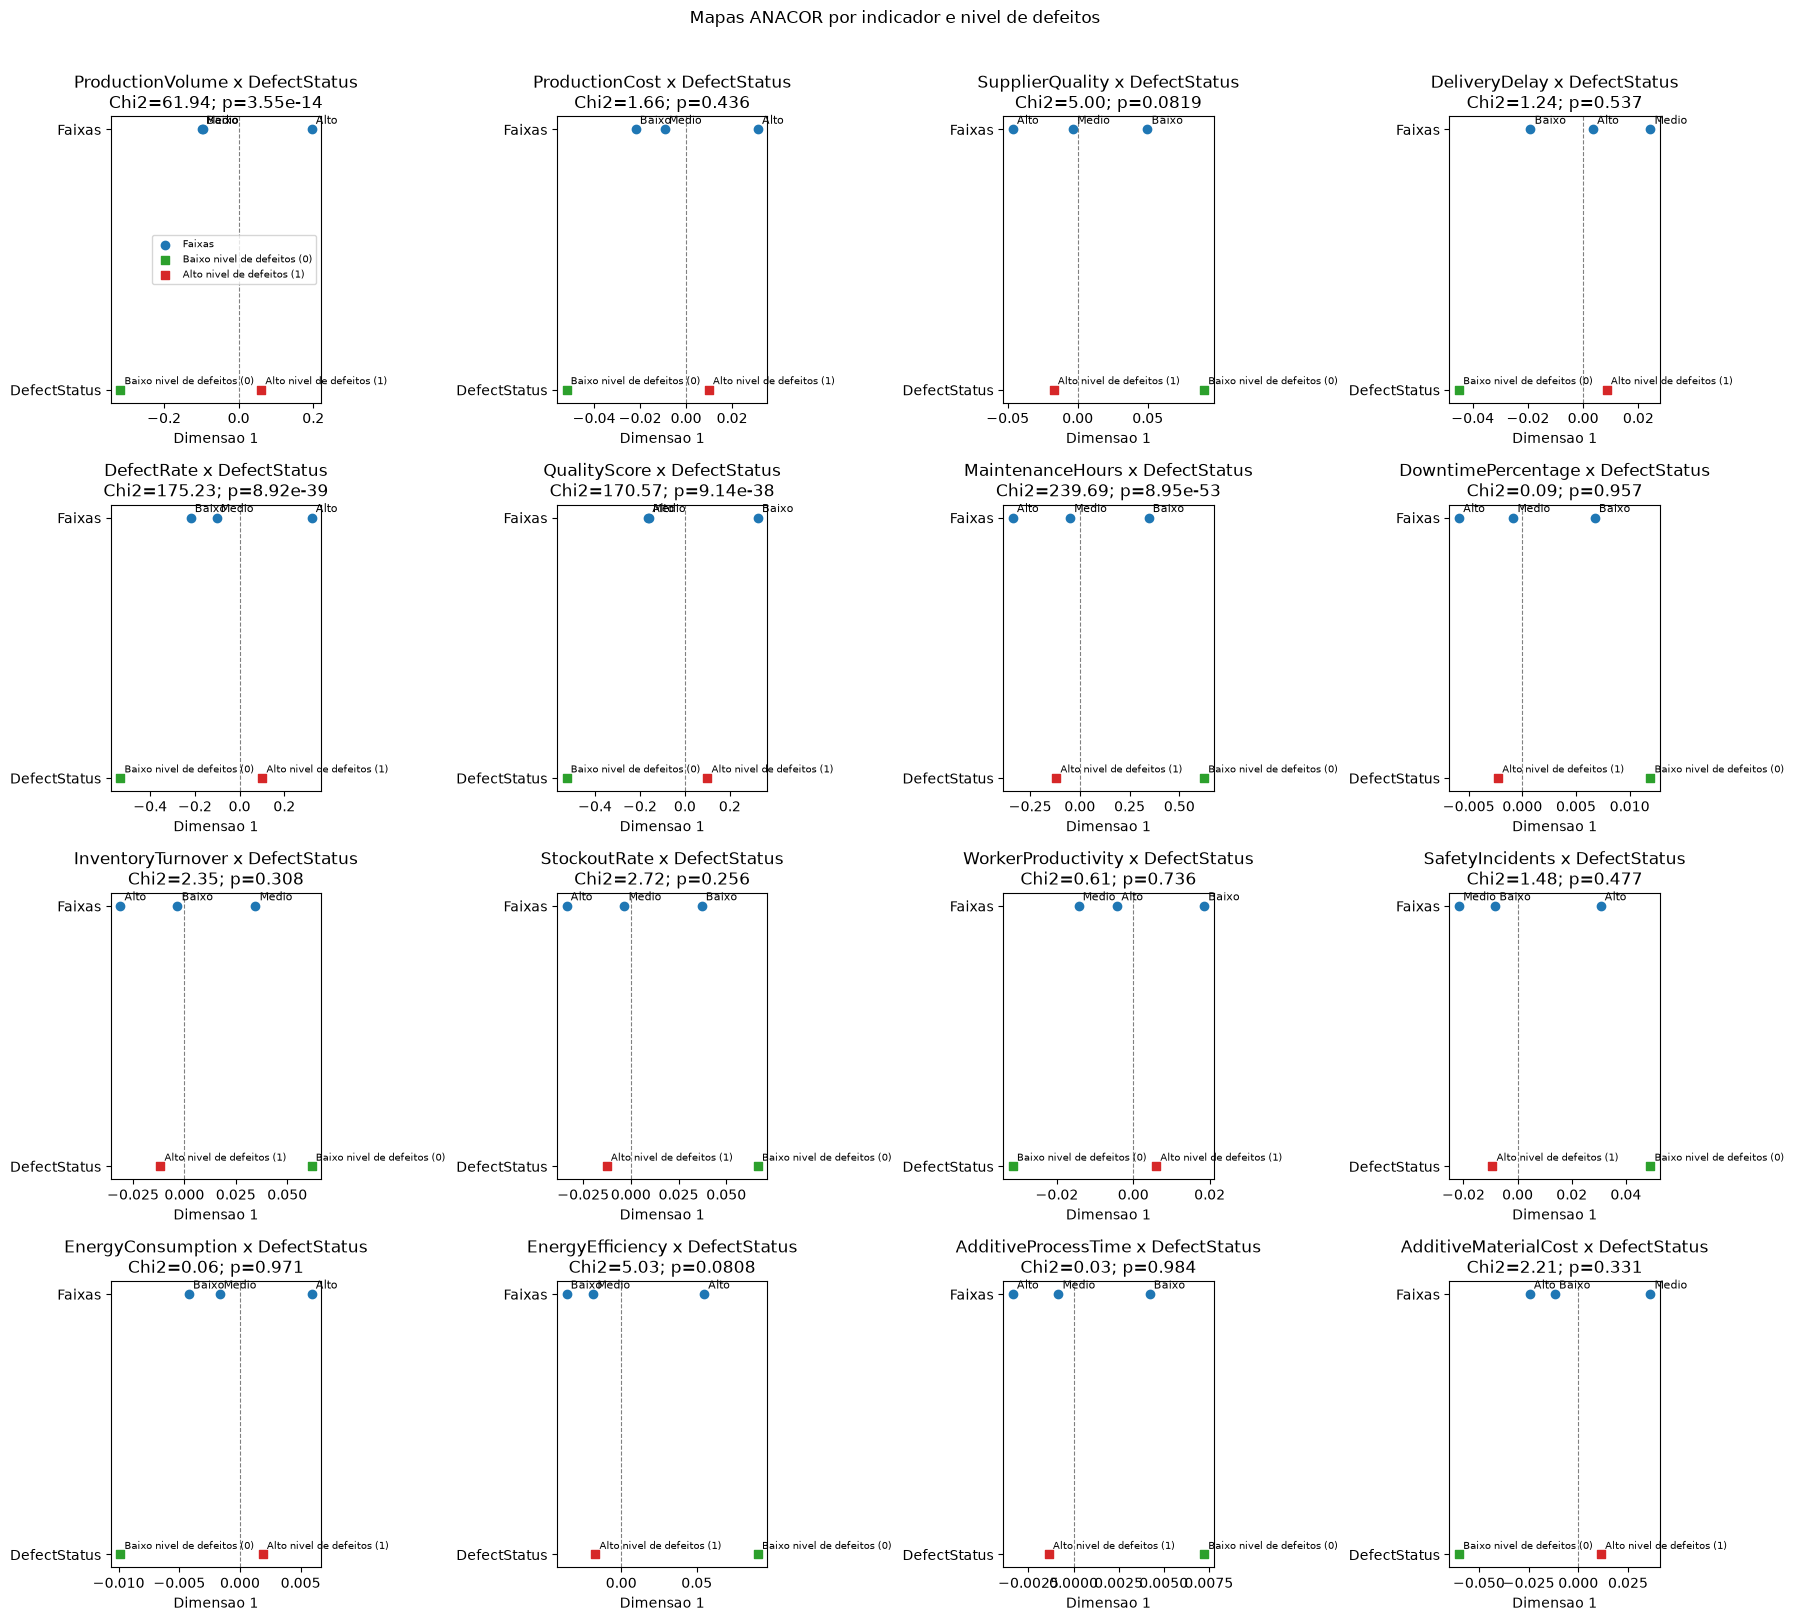

,indicador,qui_quadrado,graus_liberdade,p_valor,menor_frequencia_esperada,inercia_total
6,MaintenanceHours,239.689905,2,8.953614e-53,149.993827,0.073978
4,DefectRate,175.225328,2,8.918739e-39,172.333333,0.054082
5,QualityScore,170.571740,2,9.137289e-38,172.333333,0.052646
0,ProductionVolume,61.939484,2,3.548232e-14,172.014198,0.019117
13,EnergyEfficiency,5.031031,2,8.082124e-02,172.333333,0.001553
2,SupplierQuality,5.003413,2,8.194503e-02,172.333333,0.001544
9,StockoutRate,2.724950,2,2.560263e-01,172.333333,0.000841
8,InventoryTurnover,2.352111,2,3.084933e-01,172.333333,0.000726
15,AdditiveMaterialCost,2.214022,2,3.305455e-01,172.333333,0.000683
1,ProductionCost,1.661667,2,4.356860e-01,172.333333,0.000513


In [15]:
from scipy.stats import chi2_contingency
import prince

linhas_anacor = []
colunas_anacor = [coluna for coluna in colunas_numericas if coluna != "DefectStatus"]
rotulos_status_anacor = {0: "Baixo nivel de defeitos (0)", 1: "Alto nivel de defeitos (1)"}
cores_status_anacor = {0: "#2ca02c", 1: "#d62728"}
quantidade_colunas = 4
quantidade_linhas = (len(colunas_anacor) + quantidade_colunas - 1) // quantidade_colunas
fig, axes = plt.subplots(
    quantidade_linhas,
    quantidade_colunas,
    figsize=(18, 4 * quantidade_linhas),
    squeeze=False,
)

for ax, coluna in zip(axes.flat, colunas_anacor):
    faixas = pd.qcut(
        df[coluna],
        q=3,
        labels=["Baixo", "Medio", "Alto"],
        duplicates="drop",
    )
    dados_anacor = pd.DataFrame({"faixa": faixas, "DefectStatus": df[alvo]}).dropna()
    tabela = pd.crosstab(dados_anacor["faixa"], dados_anacor["DefectStatus"])
    qui2, p_valor, graus_liberdade, esperadas = chi2_contingency(tabela)
    anacor = prince.CA(n_components=1).fit(tabela)
    coord_faixas = anacor.row_coordinates(tabela).iloc[:, 0]
    coord_status = anacor.column_coordinates(tabela).iloc[:, 0]

    ax.scatter(coord_faixas, [1] * len(coord_faixas), label="Faixas", marker="o")
    for categoria, coordenada in coord_status.items():
        classe = int(categoria)
        rotulo = rotulos_status_anacor[classe]
        ax.scatter(
            coordenada, 0, label=rotulo, marker="s",
            color=cores_status_anacor[classe],
        )
        ax.annotate(rotulo, (coordenada, 0), xytext=(3, 4), textcoords="offset points", fontsize=7)
    for categoria, coordenada in coord_faixas.items():
        ax.annotate(str(categoria), (coordenada, 1), xytext=(3, 4), textcoords="offset points", fontsize=8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_yticks([0, 1], labels=["DefectStatus", "Faixas"])
    ax.set_xlabel("Dimensao 1")
    ax.set_title(f"{coluna} x DefectStatus\nChi2={qui2:.2f}; p={p_valor:.3g}")

    linhas_anacor.append({
        "indicador": coluna,
        "qui_quadrado": qui2,
        "graus_liberdade": graus_liberdade,
        "p_valor": p_valor,
        "menor_frequencia_esperada": esperadas.min(),
        "inercia_total": anacor.total_inertia_,
    })

for ax in axes.flat[len(colunas_anacor):]:
    ax.remove()

axes.flat[0].legend(loc="best", fontsize=7)
fig.suptitle("Mapas ANACOR por indicador e nivel de defeitos", y=1.01)
plt.tight_layout()
plt.show()

tabela_anacor = pd.DataFrame(linhas_anacor).sort_values("p_valor")
display(tabela_anacor)

## Previsao de custo e taxa de defeitos

O `RandomForestRegressor` estima `ProductionCost` (dolares por dia) e `DefectRate` (defeitos por 1.000 unidades). Os alvos e `DefectStatus` ficam fora dos preditores. A avaliacao compara o modelo com uma referencia que sempre preve a media do conjunto de treino. A celula seguinte estima os valores para um registro de producao hipotetico preenchido com medianas. O dataset e sintetico; os resultados sao demonstrativos, nao previsoes operacionais validadas.

**Atencao:** neste teste, os modelos nao superaram a referencia pela media para esses alvos. Nao trate as estimativas como previsoes confiaveis sem validacao em dados reais e temporalmente adequados.

In [16]:
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

alvos_regressao = ["ProductionCost", "DefectRate"]
features_previsao = [
    coluna
    for coluna in df.select_dtypes(include="number").columns
    if coluna not in {*alvos_regressao, "DefectStatus"}
]
X_reg = df[features_previsao]
y_reg = df[alvos_regressao]
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

modelos_regressao = {}
linhas_metricas = []
for alvo in alvos_regressao:
    modelo = RandomForestRegressor(
        n_estimators=200, random_state=42, n_jobs=-1
    )
    baseline = DummyRegressor(strategy="mean")
    modelo.fit(X_train_reg, y_train_reg[alvo])
    baseline.fit(X_train_reg, y_train_reg[alvo])
    previsoes_teste = modelo.predict(X_test_reg)
    previsoes_baseline = baseline.predict(X_test_reg)
    modelos_regressao[alvo] = modelo

    for nome, previsoes in [
        ("Random Forest", previsoes_teste),
        ("Referencia (media)", previsoes_baseline),
    ]:
        linhas_metricas.append({
            "alvo": alvo,
            "modelo": nome,
            "MAE": mean_absolute_error(y_test_reg[alvo], previsoes),
            "RMSE": np.sqrt(mean_squared_error(y_test_reg[alvo], previsoes)),
            "R2": r2_score(y_test_reg[alvo], previsoes),
        })

metricas_regressao = pd.DataFrame(linhas_metricas).set_index(["alvo", "modelo"])
display(metricas_regressao.round(3))

for alvo in alvos_regressao:
    mae_modelo = metricas_regressao.loc[(alvo, "Random Forest"), "MAE"]
    mae_baseline = metricas_regressao.loc[(alvo, "Referencia (media)"), "MAE"]
    if mae_modelo >= mae_baseline:
        print(
            f"Aviso: para {alvo}, a Random Forest n?o superou a refer?ncia pela m?dia; "
            "interprete a estimativa com cautela."
        )

novo_lote = {
    coluna: float(df[coluna].median())
    for coluna in features_previsao
}
dados_novo_lote = pd.DataFrame([novo_lote], columns=features_previsao)
previsoes_novo_lote = {
    alvo: modelos_regressao[alvo].predict(dados_novo_lote)[0]
    for alvo in alvos_regressao
}

print("\nExemplo de previsao para um registro hipotetico com valores medianos dos indicadores:")
print(f"Custo previsto: {previsoes_novo_lote['ProductionCost']:,.2f}")
print(f"DefectRate previsto (defeitos/1.000 unidades): {previsoes_novo_lote['DefectRate']:.3f}")
print("Edite o dicionario novo_lote com os indicadores do lote que deseja avaliar.")

MAE      RMSE     R2
alvo           modelo                                       
ProductionCost Random Forest       3566.695  4193.905 -0.027
               Referencia (media)  3536.470  4139.080 -0.000
DefectRate     Random Forest          1.142     1.318 -0.033
               Referencia (media)     1.132     1.307 -0.016

Aviso: para ProductionCost, a Random Forest n?o superou a refer?ncia pela m?dia; interprete a estimativa com cautela.
Aviso: para DefectRate, a Random Forest n?o superou a refer?ncia pela m?dia; interprete a estimativa com cautela.



Exemplo de previsao para um registro hipotetico com valores medianos dos indicadores:
Custo previsto: 12,732.69
DefectRate previsto (defeitos/1.000 unidades): 2.682
Edite o dicionario novo_lote com os indicadores do lote que deseja avaliar.


## Indicadores de producao e clusters (KMeans)

Esta analise cria indicadores de custo, consumo de energia e defeitos por unidade produzida, examina associacoes com a taxa de defeitos e segmenta os registros com KMeans. `DefectRate` e informado em defeitos por 1.000 unidades. `ProductionVolume * DefectRate / 1000` estima unidades defeituosas esperadas, nao uma contagem observada. `AdditiveMaterialCost` ja e custo por unidade; `MaintenanceHours` e semanal e `ProductionVolume` e diario. A segmentacao e exploratoria, nao preve defeitos nem prova causalidade.

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Indicadores calculados por registro, usando as unidades documentadas.
df_kpi = df.copy()
df_kpi["EstimatedDefectiveUnits"] = (
    df_kpi["ProductionVolume"] * df_kpi["DefectRate"] / 1000
)
df_kpi["ProductionCostPerUnit"] = (
    df_kpi["ProductionCost"] / df_kpi["ProductionVolume"]
)
df_kpi["AdditiveMaterialCostPerUnit"] = (
    df_kpi["AdditiveMaterialCost"]
)
df_kpi["EnergyPerUnit"] = (
    df_kpi["EnergyConsumption"] / df_kpi["ProductionVolume"]
)

volume_total = df_kpi["ProductionVolume"].sum()
indicadores_producao = pd.Series({
    "Registros": len(df_kpi),
    "Unidades produzidas": volume_total,
    "DefectRate media (defeitos/1.000 unidades)": df_kpi["DefectRate"].mean(),
    "DefectRate ponderada (defeitos/1.000 unidades)": (
        df_kpi["EstimatedDefectiveUnits"].sum() / volume_total * 1000
    ),
    "Unidades defeituosas esperadas (estimativa)": df_kpi["EstimatedDefectiveUnits"].sum(),
    "Custo de producao por unidade (ponderado)": (
        df_kpi["ProductionCost"].sum() / volume_total
    ),
    "Material aditivo por unidade (medio)": (
        df_kpi["AdditiveMaterialCostPerUnit"].mean()
    ),
    "Energia por unidade (ponderada)": (
        df_kpi["EnergyConsumption"].sum() / volume_total
    ),
}, name="Valor")
display(indicadores_producao.to_frame().round(3))

# Associacoes rankeadas: valores proximos de +/-1 indicam associacao monotonica.
# Correlacoes usam colunas originais, evitando relacoes induzidas por formulas.
colunas_relacao = [
    "ProductionVolume", "ProductionCost", "DefectRate", "SupplierQuality",
    "DeliveryDelay", "QualityScore", "MaintenanceHours", "DowntimePercentage",
    "InventoryTurnover", "StockoutRate", "WorkerProductivity", "SafetyIncidents",
    "EnergyConsumption", "EnergyEfficiency", "AdditiveProcessTime",
    "AdditiveMaterialCost",
]
corr_spearman = df_kpi[colunas_relacao].corr(method="spearman")
relacoes = pd.DataFrame({
    "com taxa de defeitos (rho)": corr_spearman["DefectRate"],
    "com volume produzido (rho)": corr_spearman["ProductionVolume"],
}).drop(index=["DefectRate", "ProductionVolume"])
relacoes["forca com taxa de defeitos"] = relacoes["com taxa de defeitos (rho)"].abs()
relacoes = relacoes.sort_values("forca com taxa de defeitos", ascending=False).drop(
    columns="forca com taxa de defeitos"
)
display(relacoes.round(3))

# KMeans depende de escala: padronizamos as variaveis antes de calcular distancias.
features_cluster = [
    "ProductionVolume", "ProductionCostPerUnit", "DefectRate",
    "SupplierQuality", "DeliveryDelay", "QualityScore", "MaintenanceHours",
    "DowntimePercentage", "InventoryTurnover", "StockoutRate",
    "WorkerProductivity", "SafetyIncidents", "EnergyPerUnit",
    "EnergyEfficiency", "AdditiveProcessTime", "AdditiveMaterialCostPerUnit",
]
X_cluster = df_kpi[features_cluster]
escalador_cluster = StandardScaler()
X_cluster_scaled = escalador_cluster.fit_transform(X_cluster)

# Escolhe k entre 2 e 6 pela silhueta; isso nao garante grupos naturais.
resultados_silhueta = []
modelos_kmeans = {}
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=20)
    rotulos = modelo.fit_predict(X_cluster_scaled)
    pontuacao = silhouette_score(X_cluster_scaled, rotulos)
    modelos_kmeans[k] = modelo
    resultados_silhueta.append({"k": k, "silhueta": pontuacao})

tabela_silhueta = pd.DataFrame(resultados_silhueta).set_index("k")
k_escolhido = int(tabela_silhueta["silhueta"].idxmax())
modelo_kmeans = modelos_kmeans[k_escolhido]
df_kpi["Cluster"] = modelo_kmeans.labels_
print(f"K selecionado pela maior silhueta: {k_escolhido}")
display(tabela_silhueta.round(3))

perfil_clusters = df_kpi.groupby("Cluster").agg(
    Registros=("Cluster", "size"),
    Volume_medio=("ProductionVolume", "mean"),
    DefectRate_media_defeitos_por_1000=("DefectRate", "mean"),
    Defeitos_estimados_medios=("EstimatedDefectiveUnits", "mean"),
    Custo_por_unidade_medio=("ProductionCostPerUnit", "mean"),
    Downtime_medio_pct=("DowntimePercentage", "mean"),
    Qualidade_media=("QualityScore", "mean"),
    Registros_status_alto_pct=("DefectStatus", lambda s: s.mean() * 100),
)
display(perfil_clusters.round(3))



print(
    "Os clusters descrevem grupos semelhantes nos indicadores padronizados; "
    "as associacoes sao exploratorias e nao indicam causalidade."
)

,Valor
Registros,3240.000
Unidades produzidas,1777215.000
DefectRate media (defeitos/1.000 unidades),2.749
DefectRate ponderada (defeitos/1.000 unidades),2.737
Unidades defeituosas esperadas (estimativa),4864.213
Custo de producao por unidade (ponderado),22.648
Material aditivo por unidade (medio),299.515
Energia por unidade (ponderada),5.448


,com taxa de defeitos (rho),com volume produzido (rho)
QualityScore,-0.036,0.017
AdditiveProcessTime,-0.029,-0.043
DeliveryDelay,-0.023,0.015
ProductionCost,0.014,0.029
InventoryTurnover,-0.014,0.007
EnergyEfficiency,-0.014,0.010
SupplierQuality,0.013,-0.026
AdditiveMaterialCost,0.012,-0.003
SafetyIncidents,0.012,-0.024
DowntimePercentage,-0.011,0.019


K selecionado pela maior silhueta: 2


,silhueta
k,
2,0.133
3,0.061
4,0.052
5,0.050
6,0.048


,Registros,Volume_medio,DefectRate_media_defeitos_por_1000,Defeitos_estimados_medios,Custo_por_unidade_medio,Downtime_medio_pct,Qualidade_media,Registros_status_alto_pct
Cluster,,,,,,,,
0,802,215.546,2.832,0.613,67.565,2.463,79.884,81.421
1,2438,658.059,2.722,1.793,20.376,2.514,80.217,84.906


Os clusters descrevem grupos semelhantes nos indicadores padronizados; as associacoes sao exploratorias e nao indicam causalidade.


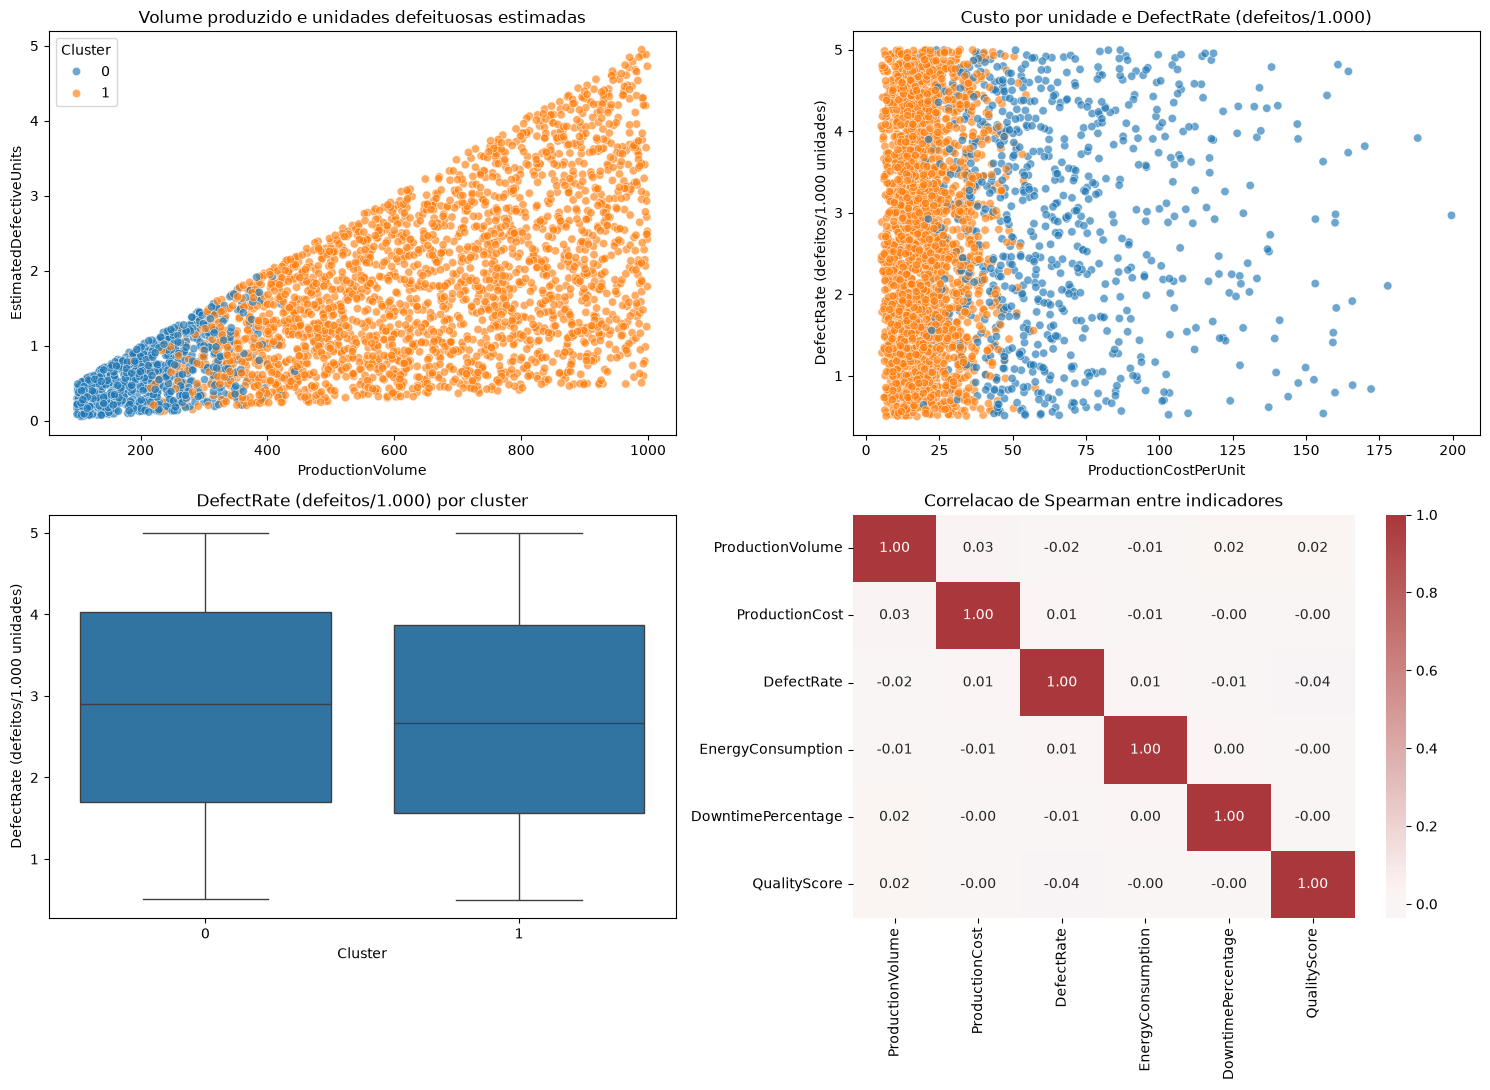

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
sns.scatterplot(
    data=df_kpi, x="ProductionVolume", y="EstimatedDefectiveUnits",
    hue="Cluster", palette="tab10", alpha=0.65, ax=axes[0, 0],
)
axes[0, 0].set_title("Volume produzido e unidades defeituosas estimadas")
sns.scatterplot(
    data=df_kpi, x="ProductionCostPerUnit", y="DefectRate",
    hue="Cluster", palette="tab10", alpha=0.65, legend=False, ax=axes[0, 1],
)
axes[0, 1].set_title("Custo por unidade e DefectRate (defeitos/1.000)")
axes[0, 1].set_ylabel("DefectRate (defeitos/1.000 unidades)")
sns.boxplot(data=df_kpi, x="Cluster", y="DefectRate", ax=axes[1, 0])
axes[1, 0].set_title("DefectRate (defeitos/1.000) por cluster")
axes[1, 0].set_ylabel("DefectRate (defeitos/1.000 unidades)")
colunas_heatmap = [
    "ProductionVolume", "ProductionCost", "DefectRate",
    "EnergyConsumption", "DowntimePercentage", "QualityScore",
]
sns.heatmap(
    df_kpi[colunas_heatmap].corr(method="spearman"),
    annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1, 1],
)
axes[1, 1].set_title("Correlacao de Spearman entre indicadores")
plt.tight_layout()
plt.show()

## Correlacoes entre variaveis e comportamento ao longo do ano

Esta celula lista as maiores correlacoes de Spearman, destaca as associacoes com `DefectRate` e `DefectStatus`, e plota a matriz completa. Correlacao nao implica causalidade. A coluna `DefectStatus` e um resultado binario; correlacoes com ela indicam associacao, nao explicacao causal. O arquivo atual nao tem uma coluna de data/calendario. `AdditiveProcessTime` e tempo de processo, nao data do ano; por isso, nao e possivel verificar sazonalidade nem afirmar que o nivel alto de defeitos aumenta em algum periodo sem registros datados.

10 maiores correlacoes em valor absoluto (inclui DefectStatus):


,variavel_1,variavel_2,spearman_rho
90,MaintenanceHours,DefectStatus,0.297
69,DefectRate,DefectStatus,0.244
80,QualityScore,DefectStatus,-0.199
15,ProductionVolume,DefectStatus,0.130
48,DeliveryDelay,DowntimePercentage,0.047
13,ProductionVolume,AdditiveProcessTime,-0.043
114,StockoutRate,DefectStatus,0.040
44,SupplierQuality,DefectStatus,0.039
93,DowntimePercentage,WorkerProductivity,-0.038
58,DefectRate,QualityScore,-0.036



10 maiores correlacoes entre indicadores, sem o resultado DefectStatus:


,variavel_1,variavel_2,spearman_rho
48,DeliveryDelay,DowntimePercentage,0.047
13,ProductionVolume,AdditiveProcessTime,-0.043
93,DowntimePercentage,WorkerProductivity,-0.038
58,DefectRate,QualityScore,-0.036
121,SafetyIncidents,EnergyConsumption,0.035
73,QualityScore,StockoutRate,-0.035
108,StockoutRate,WorkerProductivity,-0.035
109,StockoutRate,SafetyIncidents,0.032
54,DeliveryDelay,EnergyEfficiency,0.030
0,ProductionVolume,ProductionCost,0.029



Associacoes com DefectRate e DefectStatus:


,variavel,DefectRate,DefectStatus
0,MaintenanceHours,-0.009,0.297
1,QualityScore,-0.036,-0.199
2,ProductionVolume,-0.019,0.130
3,StockoutRate,0.008,0.040
4,SupplierQuality,0.013,0.039
5,EnergyEfficiency,-0.014,-0.035
6,AdditiveProcessTime,-0.029,0.006
7,ProductionCost,0.014,0.027
8,DeliveryDelay,-0.023,0.006
9,SafetyIncidents,0.012,-0.016



Nao ha coluna de data/calendario; nao e possivel testar aumento do nivel alto de defeitos por periodo do ano.


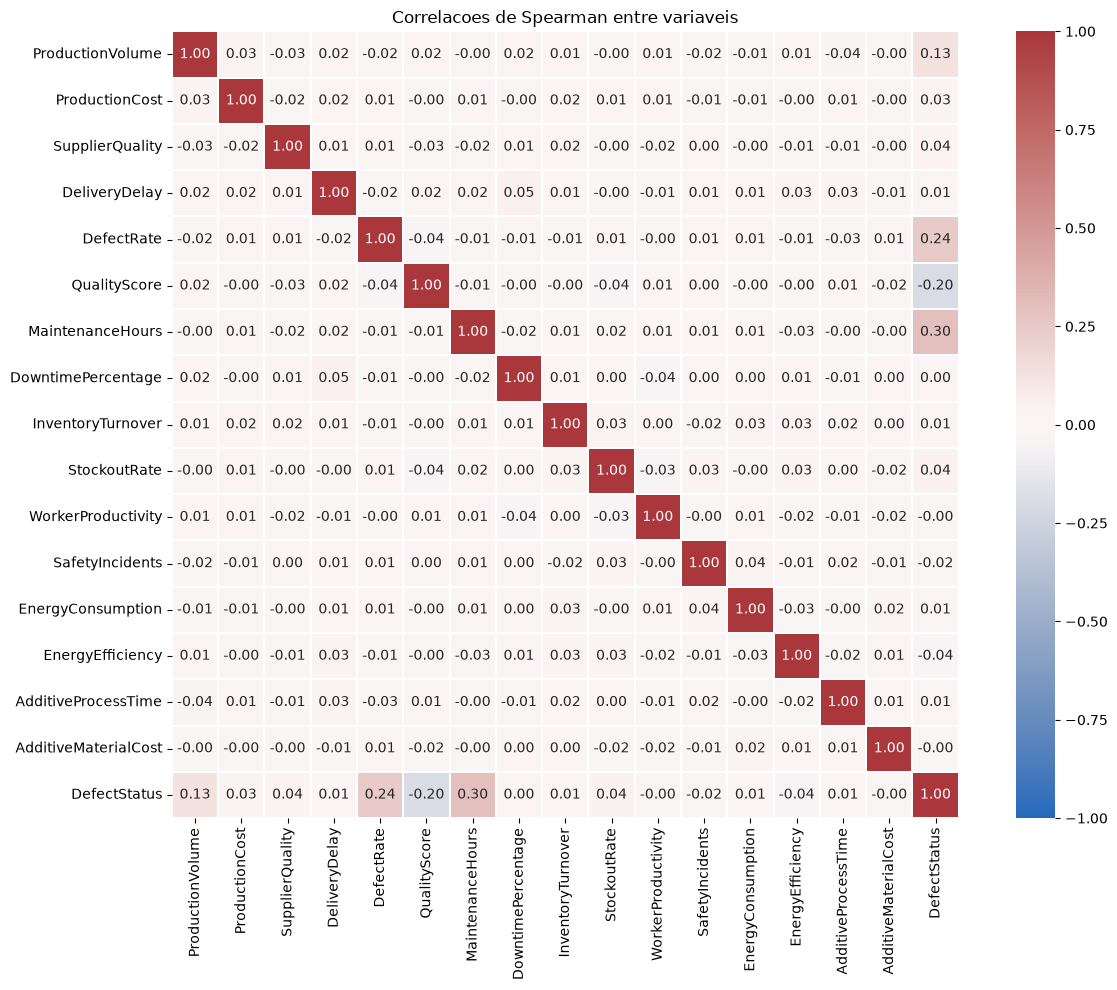

In [19]:
import re
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

colunas_corr = df.select_dtypes(include="number").columns.tolist()
corr_spearman_completa = df[colunas_corr].corr(method="spearman")
indices_i, indices_j = np.triu_indices(len(colunas_corr), k=1)
tabela_pares = pd.DataFrame({
    "variavel_1": [colunas_corr[i] for i in indices_i],
    "variavel_2": [colunas_corr[j] for j in indices_j],
    "spearman_rho": corr_spearman_completa.to_numpy()[indices_i, indices_j],
})
tabela_pares["abs_rho"] = tabela_pares["spearman_rho"].abs()
print("10 maiores correlacoes em valor absoluto (inclui DefectStatus):")
display(tabela_pares.sort_values("abs_rho", ascending=False).head(10).drop(columns="abs_rho").round(3))

pares_sem_status = tabela_pares[
    (tabela_pares["variavel_1"] != "DefectStatus")
    & (tabela_pares["variavel_2"] != "DefectStatus")
]
print()
print("10 maiores correlacoes entre indicadores, sem o resultado DefectStatus:")
display(pares_sem_status.sort_values("abs_rho", ascending=False).head(10).drop(columns="abs_rho").round(3))

print()
print("Associacoes com DefectRate e DefectStatus:")
associacoes_alvo = corr_spearman_completa[["DefectRate", "DefectStatus"]].drop(
    index=["DefectRate", "DefectStatus"], errors="ignore"
)
tabela_alvos = associacoes_alvo.reindex(
    associacoes_alvo.abs().max(axis=1).sort_values(ascending=False).index
).rename_axis("variavel").reset_index()
display(tabela_alvos.round(3))

colunas_calendario = [
    coluna for coluna in df.columns
    if re.search(
        r"(^|_)(date|data|timestamp|year|ano|month|mes|day|dia)(_|$)",
        coluna.lower(),
    )
]
colunas_datetime = df.select_dtypes(include=["datetime", "datetimetz"]).columns.tolist()
colunas_temporais = sorted(set(colunas_calendario + colunas_datetime))
if colunas_temporais:
    print()
    print(f"Colunas de calendario encontradas: {colunas_temporais}")
    print("Agrupe os registros por mes/ano antes de comparar taxa de defeitos.")
else:
    print()
    print("Nao ha coluna de data/calendario; nao e possivel testar aumento do nivel alto de defeitos por periodo do ano.")

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    corr_spearman_completa, cmap="vlag", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", square=True, linewidths=0.3, ax=ax,
)
ax.set_title("Correlacoes de Spearman entre variaveis")
plt.tight_layout()
plt.show()

## Custo do processo e previsao da taxa de defeitos

`ProductionCost` e o custo diario de producao (dolares/dia), e `DefectRate` e medido em defeitos por 1.000 unidades. A secao abaixo mede sua associacao com `DefectRate` e compara, no mesmo conjunto de teste, um baseline que preve a media, uma regressao usando apenas o custo, uma Random Forest e uma rede neural (MLP). Tambem calculamos custo e consumo por unidade. `DefectRate` e excluida dos atributos de entrada porque e o alvo; `DefectStatus` tambem e excluida para evitar usar outro resultado como preditor. Os resultados sao exploratorios: se os modelos nao superarem o baseline, nao ha evidencia de previsao util com os atributos atuais.

In [20]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Custos unitarios ajudam a comparar lotes de tamanhos diferentes.
df_modelo = df.copy()
df_modelo["ProductionCostPerUnit"] = (
    df_modelo["ProductionCost"] / df_modelo["ProductionVolume"]
)
df_modelo["AdditiveMaterialCostPerUnit"] = (
    df_modelo["AdditiveMaterialCost"] / df_modelo["ProductionVolume"]
)
df_modelo["EnergyPerUnit"] = (
    df_modelo["EnergyConsumption"] / df_modelo["ProductionVolume"]
)

alvo = "DefectRate"
features_modelo = [
    coluna for coluna in df_modelo.select_dtypes(include="number").columns
    if coluna not in {alvo, "DefectStatus"}
]
X = df_modelo[features_modelo]
y = df_modelo[alvo]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

modelo_media = DummyRegressor(strategy="mean")
modelo_custo = make_pipeline(StandardScaler(), LinearRegression())
modelo_rf = RandomForestRegressor(
    n_estimators=200, random_state=42, n_jobs=-1
)
modelo_rede = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
        alpha=0.01, learning_rate_init=0.001, max_iter=1500,
        early_stopping=True, n_iter_no_change=30, random_state=42,
    ),
)

modelo_media.fit(X_train, y_train)
modelo_custo.fit(X_train[["ProductionCost"]], y_train)
modelo_rf.fit(X_train, y_train)
modelo_rede.fit(X_train, y_train)

previsoes = {
    "Baseline (media)": modelo_media.predict(X_test),
    "Custo total apenas": modelo_custo.predict(X_test[["ProductionCost"]]),
    "Random Forest": modelo_rf.predict(X_test),
    "Rede neural (MLP)": modelo_rede.predict(X_test),
}
metricas_modelos = pd.DataFrame([
    {
        "modelo": nome,
        "MAE": mean_absolute_error(y_test, predicao),
        "RMSE": np.sqrt(mean_squared_error(y_test, predicao)),
        "R2": r2_score(y_test, predicao),
    }
    for nome, predicao in previsoes.items()
]).set_index("modelo")

defectrate_custo_spearman = df_modelo[["ProductionCost", alvo]].corr(
    method="spearman"
).loc["ProductionCost", alvo]
print(f"Spearman entre ProductionCost e DefectRate: {defectrate_custo_spearman:.3f}")
print("Metricas no teste (MAE/RMSE em defeitos por 1.000 unidades para DefectRate):")
display(metricas_modelos.round(3))
print(f"Iteracoes da rede neural: {modelo_rede[-1].n_iter_}")
melhor_modelo = metricas_modelos["MAE"].idxmin()
mae_baseline = metricas_modelos.loc["Baseline (media)", "MAE"]
mae_melhor = metricas_modelos.loc[melhor_modelo, "MAE"]
melhoria_relativa_mae = (mae_baseline - mae_melhor) / mae_baseline
r2_melhor = metricas_modelos.loc[melhor_modelo, "R2"]
if melhoria_relativa_mae < 0.01 or r2_melhor <= 0:
    print("Conclusao: nenhum modelo mostra ganho relevante sobre a media; a rede neural perde para o baseline. Os dados atuais nao sustentam previsao confiavel.")
else:
    print(f"Menor MAE no teste: {melhor_modelo}, com ganho relativo de {melhoria_relativa_mae:.1%}. Validar em outros periodos/dados antes de uso operacional.")

# Variaveis consumidas pela celula de graficos abaixo.
y_test_taxa = y_test.reset_index(drop=True)
predicoes_teste_mlp = previsoes["Rede neural (MLP)"]
predicoes_teste_media = previsoes["Baseline (media)"]
custo_teste = X_test["ProductionCost"].reset_index(drop=True)

Spearman entre ProductionCost e DefectRate: 0.014
Metricas no teste (MAE/RMSE em defeitos por 1.000 unidades para DefectRate):


,MAE,RMSE,R2
modelo,,,
Baseline (media),1.132,1.307,-0.016
Custo total apenas,1.132,1.307,-0.016
Random Forest,1.131,1.308,-0.017
Rede neural (MLP),1.175,1.375,-0.124


Iteracoes da rede neural: 92
Conclusao: nenhum modelo mostra ganho relevante sobre a media; a rede neural perde para o baseline. Os dados atuais nao sustentam previsao confiavel.


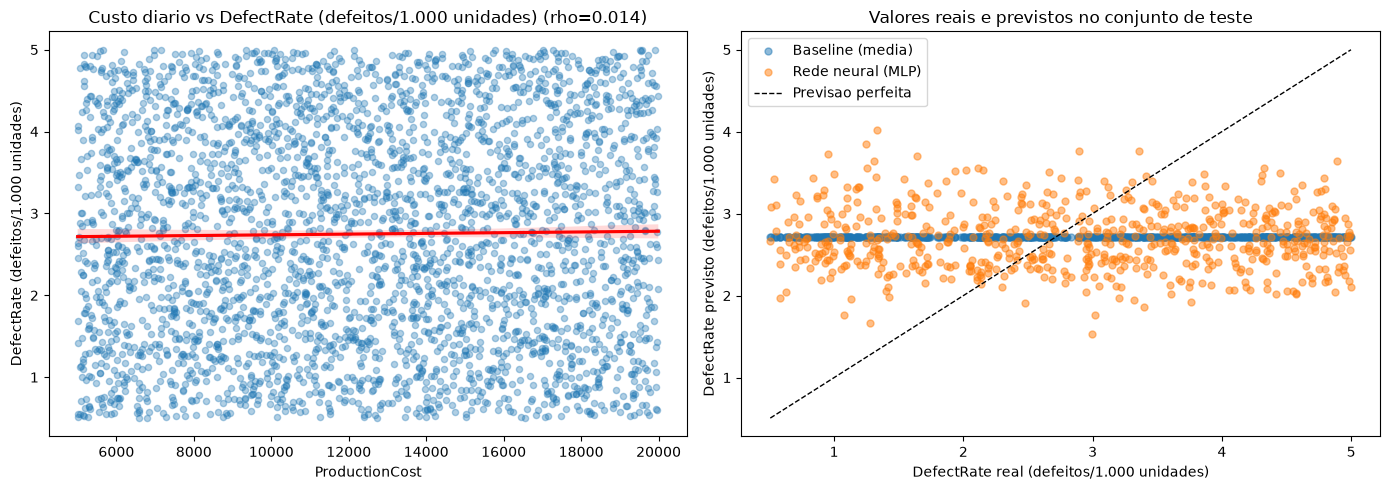

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(
    x=df_modelo["ProductionCost"], y=df_modelo["DefectRate"],
    scatter_kws={"alpha": 0.35, "s": 20}, line_kws={"color": "red"},
    ax=axes[0],
)
axes[0].set_title(f"Custo diario vs DefectRate (defeitos/1.000 unidades) (rho={defectrate_custo_spearman:.3f})")
axes[0].set_xlabel("ProductionCost")
axes[0].set_ylabel("DefectRate (defeitos/1.000 unidades)")

axes[1].scatter(
    y_test_taxa, predicoes_teste_media, alpha=0.5,
    label="Baseline (media)", s=25,
)
axes[1].scatter(
    y_test_taxa, predicoes_teste_mlp, alpha=0.5,
    label="Rede neural (MLP)", s=25,
)
limite = [
    min(float(y_test_taxa.min()), float(np.min(predicoes_teste_mlp))),
    max(float(y_test_taxa.max()), float(np.max(predicoes_teste_mlp))),
]
axes[1].plot(limite, limite, "k--", linewidth=1, label="Previsao perfeita")
axes[1].set_title("Valores reais e previstos no conjunto de teste")
axes[1].set_xlabel("DefectRate real (defeitos/1.000 unidades)")
axes[1].set_ylabel("DefectRate previsto (defeitos/1.000 unidades)")
axes[1].legend()
plt.tight_layout()
plt.show()

## Classificacao do nivel de defeitos com Random Forest

Aplicamos a mesma abordagem de classificacao ao alvo binario `DefectStatus`: separacao treino/teste estratificada, Random Forest, acuracia, relatorio de classificacao, matriz de confusao, importancia das variaveis e amostra de previsoes. `DefectRate` fica fora dos preditores por ser uma medida diretamente ligada ao nivel de defeitos e causar vazamento de informacao. As classes sao desbalanceadas (classe 0: 15,96%; classe 1: 84,04%); avalie precision e recall de ambas, nao apenas a acuracia.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

alvo_cls = "DefectStatus"
preditores_cls = [
    coluna for coluna in df.select_dtypes(include="number").columns
    if coluna not in {alvo_cls, "DefectRate"}
]
dados_cls = df[[*preditores_cls, alvo_cls]].dropna().copy()
X_cls = dados_cls[preditores_cls]
y_cls = dados_cls[alvo_cls].astype(int)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)
clf_defeitos = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=10, class_weight="balanced", random_state=42
)
clf_defeitos.fit(X_train_cls, y_train_cls)
y_pred_cls = clf_defeitos.predict(X_test_cls)

acuracia_cls = accuracy_score(y_test_cls, y_pred_cls)
matriz_confusao_cls = confusion_matrix(y_test_cls, y_pred_cls, labels=[0, 1])
print(f"Acuracia: {acuracia_cls:.2%}")
print("Relatorio de classificacao:")
print(classification_report(
    y_test_cls, y_pred_cls, labels=[0, 1],
    target_names=["Baixo nivel de defeitos", "Alto nivel de defeitos"],
    zero_division=0,
))
print("Matriz de confusao (linhas=real, colunas=previsto; ordem [0, 1]):")
display(pd.DataFrame(
    matriz_confusao_cls,
    index=["Real: baixo nivel (0)", "Real: alto nivel (1)"],
    columns=["Previsto: baixo nivel (0)", "Previsto: alto nivel (1)"],
))
print(f"Registros usados: {len(dados_cls)}; treino: {len(X_train_cls)}; teste: {len(X_test_cls)}")
print(f"Preditores usados (sem DefectRate e DefectStatus): {len(preditores_cls)}")

Acuracia: 85.96%
Relatorio de classificacao:
                         precision    recall  f1-score   support

Baixo nivel de defeitos       0.54      0.74      0.63       103
 Alto nivel de defeitos       0.95      0.88      0.91       545

               accuracy                           0.86       648
              macro avg       0.74      0.81      0.77       648
           weighted avg       0.88      0.86      0.87       648

Matriz de confusao (linhas=real, colunas=previsto; ordem [0, 1]):


,Previsto: baixo nivel (0),Previsto: alto nivel (1)
Real: baixo nivel (0),76,27
Real: alto nivel (1),64,481


Registros usados: 3240; treino: 2592; teste: 648
Preditores usados (sem DefectRate e DefectStatus): 15


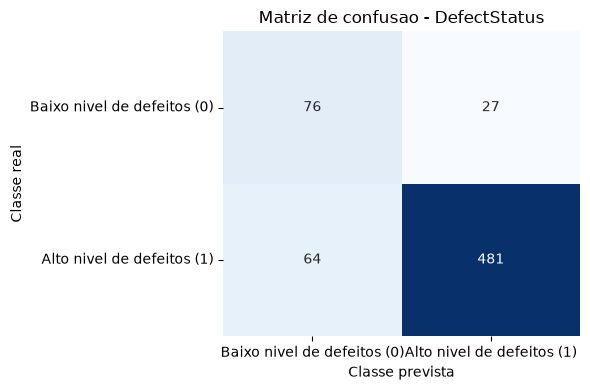

In [23]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(
    matriz_confusao_cls, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Baixo nivel de defeitos (0)", "Alto nivel de defeitos (1)"],
    yticklabels=["Baixo nivel de defeitos (0)", "Alto nivel de defeitos (1)"], ax=ax,
)
ax.set_title("Matriz de confusao - DefectStatus")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

Importancia das 10 principais variaveis (impureza; nao indica causalidade):


,Importancia
MaintenanceHours,0.3761
QualityScore,0.2117
ProductionVolume,0.1331
StockoutRate,0.0340
AdditiveMaterialCost,0.0333
SupplierQuality,0.0278
EnergyConsumption,0.0258
InventoryTurnover,0.0245
EnergyEfficiency,0.0245
ProductionCost,0.0228


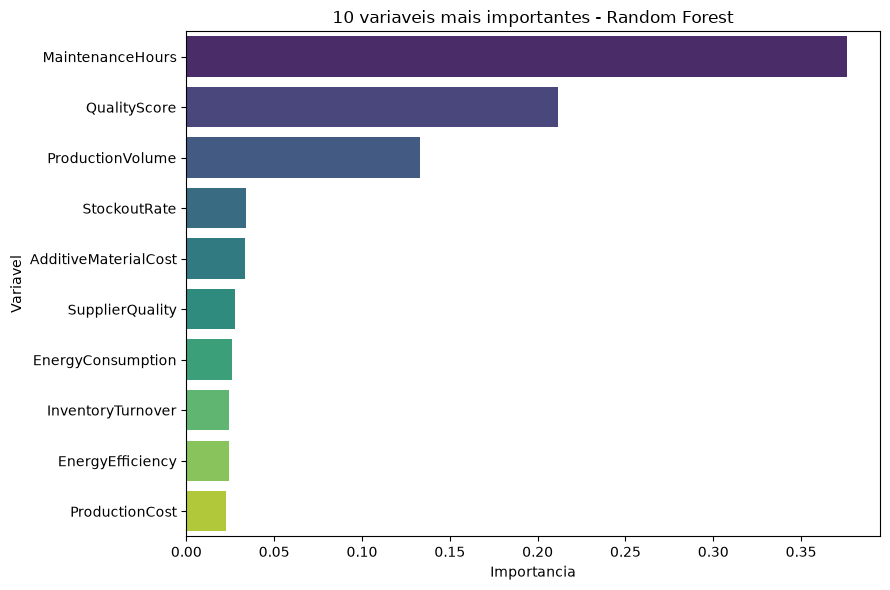

In [24]:
importancias_cls = pd.Series(
    clf_defeitos.feature_importances_, index=preditores_cls
).sort_values(ascending=False)
print("Importancia das 10 principais variaveis (impureza; nao indica causalidade):")
display(importancias_cls.head(10).to_frame("Importancia").round(4))

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(
    x=importancias_cls.head(10).values,
    y=importancias_cls.head(10).index,
    hue=importancias_cls.head(10).index,
    palette="viridis", legend=False, ax=ax,
)
ax.set_title("10 variaveis mais importantes - Random Forest")
ax.set_xlabel("Importancia")
ax.set_ylabel("Variavel")
plt.tight_layout()
plt.show()

In [25]:
previsoes_amostra_cls = pd.DataFrame({
    "Real": y_test_cls.to_numpy(),
    "Previsto": y_pred_cls,
})
print("Amostra de 10 previsoes no conjunto de teste:")
display(previsoes_amostra_cls.head(10))

Amostra de 10 previsoes no conjunto de teste:


,Real,Previsto
0,1,1
1,1,1
2,1,1
3,1,1
4,0,0
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


## QualityScore e MaintenanceHours por DefectStatus

Comparamos a media e a mediana de `QualityScore` e `MaintenanceHours` entre registros baixo nivel de defeitos (`DefectStatus=0`) e alto nivel de defeitos (`DefectStatus=1`). A correlacao de Spearman trata o status binario como 0/1; o sinal indica a direcao da associacao, mas nao causalidade. O teste de Welch compara medias e os p-valores sao ajustados pelo metodo de Holm para as duas variaveis. MaintenanceHours esta documentada por semana, enquanto o volume e diario; sem data ou periodo comum por linha, a comparacao e associativa e nao temporal. Diferencas estatisticamente significativas nao provam causalidade.

Resumo por grupo:


,variavel,status,n,media,mediana,desvio_padrao
0,QualityScore,Baixo nivel de defeitos (0),517,85.442,85.864,9.238
1,QualityScore,Alto nivel de defeitos (1),2723,79.126,78.575,11.743
2,MaintenanceHours,Baixo nivel de defeitos (0),517,6.791,6.000,5.096
3,MaintenanceHours,Alto nivel de defeitos (1),2723,12.366,13.000,6.806



Diferencas e associacoes (diferenca = DefectStatus 1 menos 0):


,variavel,diferenca_media (1 - 0),variacao_percentual_vs_0 (%),spearman_rho,p_welch,p_mann_whitney,p_spearman,p_welch_holm,p_mann_whitney_holm,p_spearman_holm
0,QualityScore,-6.31592,-7.39202,-0.19856,2.58e-38,1.31e-29,3.67e-30,2.58e-38,1.31e-29,3.67e-30
1,MaintenanceHours,5.57504,82.09326,0.29715,3.72e-83,3.71e-64,4.74e-67,7.44e-83,7.43e-64,9.47e-67



Direcao observada:
QualityScore: diminui 6.316 (-7.4%) em media quando DefectStatus=1; Spearman rho=-0.199, p de Welch ajustado (Holm)=2.58e-38.
MaintenanceHours: aumenta 5.575 (+82.1%) em media quando DefectStatus=1; Spearman rho=+0.297, p de Welch ajustado (Holm)=7.44e-83.


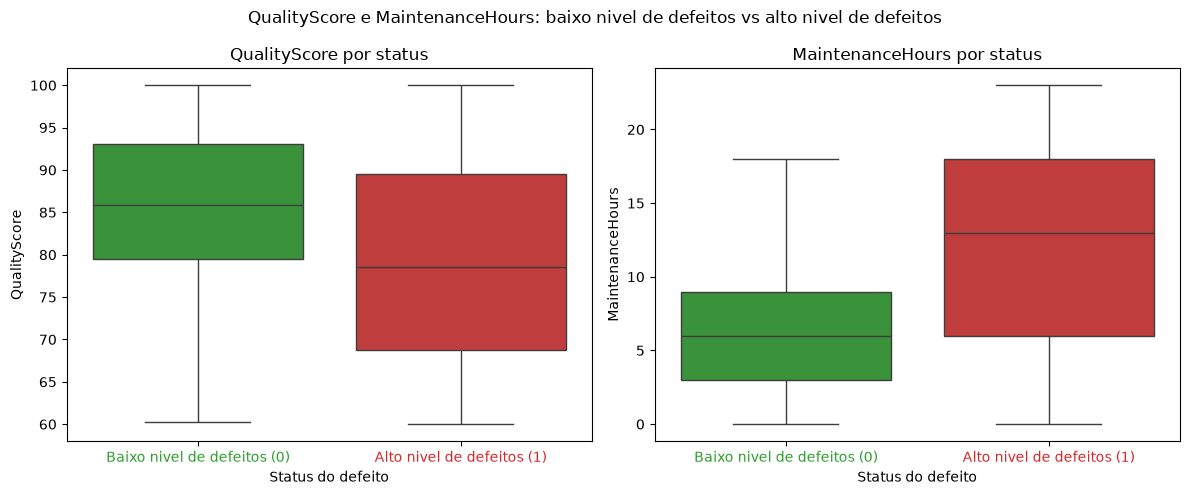

In [26]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, spearmanr, ttest_ind
from statsmodels.stats.multitest import multipletests

variaveis_comparacao = ["QualityScore", "MaintenanceHours"]
dados_comparacao = df[["DefectStatus", *variaveis_comparacao]].dropna().copy()
dados_comparacao["DefectStatus"] = dados_comparacao["DefectStatus"].astype(int)
rotulos_status = {0: "Baixo nivel de defeitos (0)", 1: "Alto nivel de defeitos (1)"}
cores_status = {0: "#2ca02c", 1: "#d62728"}

linhas_grupos = []
linhas_testes = []
for variavel in variaveis_comparacao:
    sem_defeito = dados_comparacao.loc[dados_comparacao["DefectStatus"] == 0, variavel]
    com_defeito = dados_comparacao.loc[dados_comparacao["DefectStatus"] == 1, variavel]
    rho, p_spearman = spearmanr(dados_comparacao["DefectStatus"], dados_comparacao[variavel])
    _, p_welch = ttest_ind(com_defeito, sem_defeito, equal_var=False)
    _, p_mann_whitney = mannwhitneyu(sem_defeito, com_defeito, alternative="two-sided")
    diferenca_media = com_defeito.mean() - sem_defeito.mean()
    mudanca_percentual = diferenca_media / abs(sem_defeito.mean()) * 100

    linhas_grupos.extend([
        {
            "variavel": variavel,
            "status": rotulos_status[0],
            "n": len(sem_defeito),
            "media": sem_defeito.mean(),
            "mediana": sem_defeito.median(),
            "desvio_padrao": sem_defeito.std(),
        },
        {
            "variavel": variavel,
            "status": rotulos_status[1],
            "n": len(com_defeito),
            "media": com_defeito.mean(),
            "mediana": com_defeito.median(),
            "desvio_padrao": com_defeito.std(),
        },
    ])
    linhas_testes.append({
        "variavel": variavel,
        "diferenca_media (1 - 0)": diferenca_media,
        "variacao_percentual_vs_0 (%)": mudanca_percentual,
        "spearman_rho": rho,
        "p_welch": p_welch,
        "p_mann_whitney": p_mann_whitney,
        "p_spearman": p_spearman,
    })

tabela_grupos = pd.DataFrame(linhas_grupos)
tabela_testes = pd.DataFrame(linhas_testes)
for coluna_p in ["p_welch", "p_mann_whitney", "p_spearman"]:
    tabela_testes[coluna_p + "_holm"] = multipletests(
        tabela_testes[coluna_p], method="holm"
    )[1]

print("Resumo por grupo:")
display(tabela_grupos.round(3))
print("\nDiferencas e associacoes (diferenca = DefectStatus 1 menos 0):")
tabela_testes_exibicao = tabela_testes.copy()
for coluna_p in [
    "p_welch", "p_mann_whitney", "p_spearman",
    "p_welch_holm", "p_mann_whitney_holm", "p_spearman_holm",
]:
    tabela_testes_exibicao[coluna_p] = tabela_testes_exibicao[coluna_p].map(
        lambda valor: f"{valor:.2e}"
    )
display(tabela_testes_exibicao.round(5))
print("\nDirecao observada:")
for _, linha in tabela_testes.iterrows():
    direcao = "aumenta" if linha["diferenca_media (1 - 0)"] > 0 else "diminui"
    print(
        f"{linha['variavel']}: {direcao} {abs(linha['diferenca_media (1 - 0)']):.3f} "
        f"({linha['variacao_percentual_vs_0 (%)']:+.1f}%) em media quando DefectStatus=1; "
        f"Spearman rho={linha['spearman_rho']:+.3f}, "
        f"p de Welch ajustado (Holm)={linha['p_welch_holm']:.3g}."
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, variavel in zip(axes, variaveis_comparacao):
    sns.boxplot(
        data=dados_comparacao, x="DefectStatus", y=variavel,
        hue="DefectStatus", hue_order=[0, 1], palette=cores_status,
        dodge=False, legend=False, showfliers=False, ax=ax,
    )
    ax.set_xticks([0, 1], labels=[rotulos_status[0], rotulos_status[1]])
    ax.set_xlabel("Status do defeito")
    ax.set_title(f"{variavel} por status")
    ax.set_ylabel(variavel)
    for tick, classe in zip(ax.get_xticklabels(), [0, 1]):
        tick.set_color(cores_status[classe])
fig.suptitle("QualityScore e MaintenanceHours: baixo nivel de defeitos vs alto nivel de defeitos")
plt.tight_layout()
plt.show()

## QualityScore x MaintenanceHours por status de defeito

A relacao entre qualidade e manutencao pode mudar conforme `DefectStatus`. Abaixo, calculamos Spearman no total e separadamente por status, alem de uma regressao com interacao `QualityScore * DefectStatus` para testar se as inclinacoes diferem entre os grupos. O grafico separa os status para evitar esconder essa diferenca. Associacao nao implica causalidade.

Associacao monot?nica (Spearman) entre QualityScore e horas de manutencao:


,grupo,n,QualityScore medio,MaintenanceHours medio,Spearman rho,p-valor Spearman
0,Todos,3240,80.1343,11.4765,-0.0136,4.401e-01
1,Baixo nivel de defeitos (0),517,85.4424,6.7911,-0.1643,1.760e-04
2,Alto nivel de defeitos (1),2723,79.1265,12.3661,0.0785,4.095e-05



Regressao com interacao (erro-padrao robusto HC3):
Inclinacao no status 0: -0.1242 horas por ponto de QualityScore (EP 0.0268)
Inclinacao no status 1: +0.0461 horas por ponto de QualityScore (EP 0.0112)
Teste de diferenca entre inclinacoes (interacao): p=4.370e-09


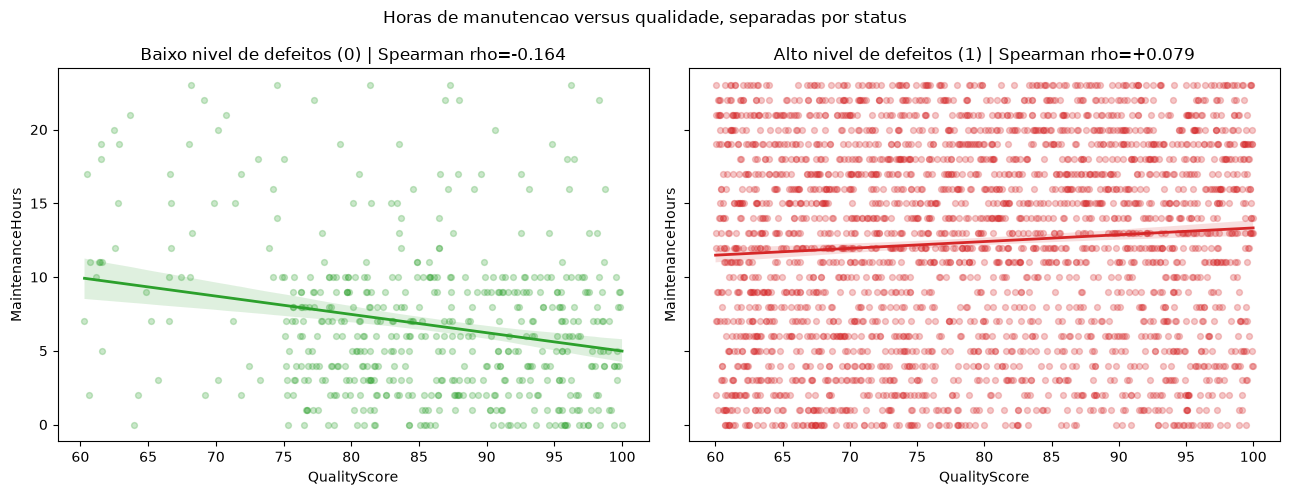

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import statsmodels.formula.api as smf

status_labels = {0: "Baixo nivel de defeitos (0)", 1: "Alto nivel de defeitos (1)"}
status_colors = {0: "#2ca02c", 1: "#d62728"}
dados_score_manutencao = df[["QualityScore", "MaintenanceHours", "DefectStatus"]].dropna().copy()
dados_score_manutencao["DefectStatus"] = dados_score_manutencao["DefectStatus"].astype(int)

resultados_score_manutencao = []
for status in [None, 0, 1]:
    grupo = dados_score_manutencao if status is None else dados_score_manutencao[
        dados_score_manutencao["DefectStatus"] == status
    ]
    rho, p_valor = spearmanr(grupo["QualityScore"], grupo["MaintenanceHours"])
    resultados_score_manutencao.append({
        "grupo": "Todos" if status is None else status_labels[status],
        "n": len(grupo),
        "QualityScore medio": grupo["QualityScore"].mean(),
        "MaintenanceHours medio": grupo["MaintenanceHours"].mean(),
        "Spearman rho": rho,
        "p-valor Spearman": p_valor,
    })

tabela_relacao_score_manutencao = pd.DataFrame(resultados_score_manutencao)
modelo_interacao = smf.ols(
    "MaintenanceHours ~ QualityScore * C(DefectStatus)",
    data=dados_score_manutencao,
).fit(cov_type="HC3")
coef_base = modelo_interacao.params["QualityScore"]
termo_interacao = "QualityScore:C(DefectStatus)[T.1]"
coef_interacao = modelo_interacao.params[termo_interacao]
variancia = modelo_interacao.cov_params()

# Inclina??es ajustadas por grupo e seus erros padr?o robustos.
inclinacao_status_0 = coef_base
se_status_0 = np.sqrt(variancia.loc["QualityScore", "QualityScore"])
inclinacao_status_1 = coef_base + coef_interacao
se_status_1 = np.sqrt(
    variancia.loc["QualityScore", "QualityScore"]
    + variancia.loc[termo_interacao, termo_interacao]
    + 2 * variancia.loc["QualityScore", termo_interacao]
)
p_interacao = modelo_interacao.pvalues[termo_interacao]

print("Associacao monot?nica (Spearman) entre QualityScore e horas de manutencao:")
tabela_exibicao = tabela_relacao_score_manutencao.copy()
tabela_exibicao["p-valor Spearman"] = tabela_exibicao["p-valor Spearman"].map(
    lambda valor: f"{valor:.3e}"
)
display(tabela_exibicao.round(4))
print("\nRegressao com interacao (erro-padrao robusto HC3):")
print(f"Inclinacao no status 0: {inclinacao_status_0:+.4f} horas por ponto de QualityScore (EP {se_status_0:.4f})")
print(f"Inclinacao no status 1: {inclinacao_status_1:+.4f} horas por ponto de QualityScore (EP {se_status_1:.4f})")
print(f"Teste de diferenca entre inclinacoes (interacao): p={p_interacao:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, status in zip(axes, [0, 1]):
    grupo = dados_score_manutencao[dados_score_manutencao["DefectStatus"] == status]
    rho = tabela_relacao_score_manutencao.loc[
        tabela_relacao_score_manutencao["grupo"] == status_labels[status],
        "Spearman rho",
    ].iloc[0]
    sns.regplot(
        data=grupo, x="QualityScore", y="MaintenanceHours", ax=ax,
        color=status_colors[status],
        scatter_kws={"alpha": 0.25, "s": 18},
        line_kws={"linewidth": 2},
    )
    ax.set_title(f"{status_labels[status]} | Spearman rho={rho:+.3f}")
    ax.set_xlabel("QualityScore")
    ax.set_ylabel("MaintenanceHours")
fig.suptitle("Horas de manutencao versus qualidade, separadas por status")
plt.tight_layout()
plt.show()

## Comparar nivel alto de defeitos por faixa de SupplierQuality

Este arquivo nao possui nome nem identificador de fornecedor. Portanto, nao e possivel dizer qual fornecedor real tem maior proporcao de registros com nivel alto de defeitos. Para uma comparacao descritiva sem inventar fornecedores, este novo DataFrame agrupa os 3.240 registros em tres faixas de `SupplierQuality` (baixa, media e alta), com o mesmo numero de registros por faixa. Cada linha da tabela representa uma faixa, nao um fornecedor.

In [28]:
import pandas as pd

# Grupos de mesmo tamanho pelo indicador de qualidade do fornecedor.
dados_fornecedor = df.copy()
dados_fornecedor["FaixaSupplierQuality"] = pd.qcut(
    dados_fornecedor["SupplierQuality"],
    q=3,
    labels=["Baixa", "Media", "Alta"],
)
limites_faixas = dados_fornecedor.groupby(
    "FaixaSupplierQuality", observed=True
)["SupplierQuality"].agg(minimo="min", maximo="max")

# Novo DataFrame resumido: uma linha por faixa de SupplierQuality.
df_faixas_supplierquality = (
    dados_fornecedor.groupby("FaixaSupplierQuality", observed=True)
    .agg(
        Registros=("DefectStatus", "size"),
        Registros_Status_Alto=("DefectStatus", "sum"),
        Proporcao_Status_Alto_pct=("DefectStatus", "mean"),
        DefectRate_media_defeitos_por_1000=("DefectRate", "mean"),
        Volume_producao_medio=("ProductionVolume", "mean"),
        QualityScore_medio=("QualityScore", "mean"),
    )
    .join(limites_faixas)
    .reset_index()
)
df_faixas_supplierquality["Proporcao_Status_Alto_pct"] *= 100
incidencia_global = dados_fornecedor["DefectStatus"].mean() * 100

display(df_faixas_supplierquality[[
    "FaixaSupplierQuality", "minimo", "maximo", "Registros",
    "Registros_Status_Alto", "Proporcao_Status_Alto_pct",
    "DefectRate_media_defeitos_por_1000", "Volume_producao_medio", "QualityScore_medio",
]].rename(columns={
    "FaixaSupplierQuality": "Faixa SupplierQuality",
    "minimo": "SupplierQuality minimo",
    "maximo": "SupplierQuality maximo",
    "Registros": "Quantidade de registros",
    "Registros_Status_Alto": "Registros com DefectStatus=1",
    "Proporcao_Status_Alto_pct": "Registros com alto nivel de defeitos (%)",
    "DefectRate_media_defeitos_por_1000": "DefectRate media (defeitos/1.000 unidades)",
    "Volume_producao_medio": "Volume medio produzido",
    "QualityScore_medio": "QualityScore medio",
}).round(2))
print(f"Proporcao geral com alto nivel (DefectStatus=1): {incidencia_global:.2f}%")
print("Cada faixa representa um terco dos registros; nao corresponde a um fornecedor real.")

,Faixa SupplierQuality,SupplierQuality minimo,SupplierQuality maximo,Quantidade de registros,Registros com DefectStatus=1,Registros com alto nivel de defeitos (%),DefectRate media (defeitos/1.000 unidades),Volume medio produzido,QualityScore medio
0,Baixa,80.00,86.43,1080,888,82.22,2.73,556.64,80.64
1,Media,86.46,92.99,1080,909,84.17,2.73,549.37,80.10
2,Alta,93.00,99.99,1080,926,85.74,2.78,539.56,79.66


Proporcao geral com alto nivel (DefectStatus=1): 84.04%
Cada faixa representa um terco dos registros; nao corresponde a um fornecedor real.


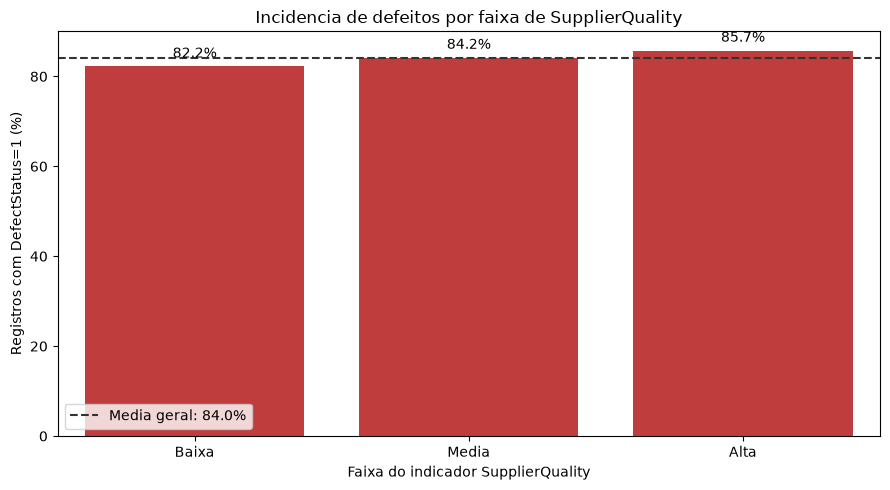

In [29]:
ordem_faixas = ["Baixa", "Media", "Alta"]
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=df_faixas_supplierquality,
    x="FaixaSupplierQuality",
    y="Proporcao_Status_Alto_pct",
    order=ordem_faixas,
    color="#d62728",
    ax=ax,
)
ax.axhline(
    incidencia_global, color="#333333", linestyle="--",
    label=f"Media geral: {incidencia_global:.1f}%",
)
for barra, valor in zip(ax.patches, df_faixas_supplierquality["Proporcao_Status_Alto_pct"]):
    ax.annotate(
        f"{valor:.1f}%", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        ha="center", va="bottom", xytext=(0, 4), textcoords="offset points",
    )
ax.set_xlabel("Faixa do indicador SupplierQuality")
ax.set_ylabel("Registros com DefectStatus=1 (%)")
ax.set_title("Incidencia de defeitos por faixa de SupplierQuality")
ax.legend()
plt.tight_layout()
plt.show()